Pour résumer la partie EDA du Projet, les points importants a remarquer sont les suivants:

* Valeurs Manquantes: dépendamment de la méthode d'intersection avec la carte de l'Algérie, quelques points a la frontière nord du pays contiennent des valeurs manquantes
* Variabilité: Certaines Features ont une très faible variabilité
* Histogram & Boxplot: Les Features très asymétriques avec une grande proportion qui parait être des outliers
* Monthly variation plot: Les Incohérences des valeurs des Monthly average de certaines Features entre 2022 et 2024
* Correlation matrix: les fortes corrélations entre certaines paires de Features (en choisissant la bonne formule de corrélation)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
DATA_DIR = "/content/drive/MyDrive/DataMining_Climat/data"
os.makedirs(DATA_DIR, exist_ok=True)

Mounted at /content/drive


In [ ]:
!pip install -q "cdsapi>=0.7.0" xarray cfgrib eccodes
!apt-get -qq install -y libeccodes-dev
!pip install -q cdsapi geopandas netcdf4 h5netcdf
!pip install -q geopandas regionmask

Selecting previously unselected package libeccodes-data.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../libeccodes-data_2.34.1-1build2_all.deb ...
Unpacking libeccodes-data (2.34.1-1build2) ...
Selecting previously unselected package libeccodes0:amd64.
Preparing to unpack .../libeccodes0_2.34.1-1build2_amd64.deb ...
Unpacking libeccodes0:amd64 (2.34.1-1build2) ...
Selecting previously unselected package libeccodes-dev:amd64.
Preparing to unpack .../libeccodes-dev_2.34.1-1build2_amd64.deb ...
Unpacking libeccodes-dev:amd64 (2.34.1-1build2) ...
Setting up libeccodes-data (2.34.1-1build2) ...
Setting up libeccodes0:amd64 (2.34.1-1build2) ...
Setting up libeccodes-dev:amd64 (2.34.1-1build2) ...
Processing triggers for libc-bin (2.39-0ubuntu8.9) ...
/sbin/ldconfig.real: /usr/local/lib/libur_adapter_level_zero_v2.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_loader.so.0 is not a symbolic link

/sbin/ldconfig.real: /us

In [ ]:
import os, glob, math, zipfile, tempfile
from datetime import date
import numpy as np
import xarray as xr
import geopandas as gpd
import cdsapi
from shapely import contains_xy
from shapely.ops import unary_union
from google.colab import drive, userdata
import xarray as xr, geopandas as gpd, regionmask, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

In [ ]:
BASE    = "/content/drive/MyDrive/DataMining_Climat"
DATA_DIR = f"{BASE}/data_nc"        # fichiers bruts NetCDF (nouveau dossier)
OUT_DIR  = f"{BASE}/processed"
SHP      = f"{BASE}/dz_shp/dz.shp"
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

START_YEAR = 2015
LAG_MONTHS = 2
FACTOR     = 2

VARS_CDS = ["2m_temperature", "2m_dewpoint_temperature", "surface_latent_heat_flux",
            "surface_net_solar_radiation", "surface_net_thermal_radiation",
            "surface_sensible_heat_flux", "runoff", "total_evaporation",
            "10m_u_component_of_wind", "10m_v_component_of_wind",
            "surface_pressure", "total_precipitation"]
VARS = ["t2m","d2m","sp","u10","v10","slhf","sshf","ssr","str","e","ro","tp"]

In [ ]:
PATH = f"{OUT_DIR}/era5land_algeria_masked_x2_corrected.nc"
ds_dz = xr.open_dataset(PATH)
print(ds_dz)
print(list(ds_dz.data_vars))

<xarray.Dataset> Size: 64MB
Dimensions:    (time: 140, latitude: 92, longitude: 104)
Coordinates:
  * time       (time) datetime64[ns] 1kB 2015-01-01 2015-02-01 ... 2026-08-01
  * latitude   (latitude) float64 736B 18.95 19.15 19.35 ... 36.75 36.95 37.1
  * longitude  (longitude) float64 832B -8.65 -8.45 -8.25 ... 11.55 11.75 11.95
    number     int64 8B ...
    expver     (time) <U4 2kB ...
Data variables:
    t2m        (time, latitude, longitude) float32 5MB ...
    d2m        (time, latitude, longitude) float32 5MB ...
    slhf       (time, latitude, longitude) float32 5MB ...
    ssr        (time, latitude, longitude) float32 5MB ...
    str        (time, latitude, longitude) float32 5MB ...
    sshf       (time, latitude, longitude) float32 5MB ...
    ro         (time, latitude, longitude) float32 5MB ...
    e          (time, latitude, longitude) float32 5MB ...
    u10        (time, latitude, longitude) float32 5MB ...
    v10        (time, latitude, longitude) float32 5MB ..

# **Missing values**

## **Point geographiquemnet valides:**

In [ ]:
PATH_1 = f"{OUT_DIR}/era5land_merged_box_raw_corrected.nc"

ds_raw = xr.open_dataset(PATH_1)

# Trier les coordonnées
ds_raw = ds_raw.sortby("latitude").sortby("longitude")

print(ds_raw.sizes)

Frozen({'valid_time': 140, 'latitude': 183, 'longitude': 208})


In [ ]:
gdf = gpd.read_file(SHP)
if gdf.crs is not None and gdf.crs.to_epsg() != 4326:
    gdf = gdf.to_crs(epsg=4326)

dz = gdf.dissolve()                        # un seul polygone Algérie
geometry = unary_union(dz.geometry)

west, south, east, north = dz.total_bounds
AREA = [math.ceil(north*10)/10,            # N : arrondi vers l'extérieur à 0.1°
        math.floor(west*10)/10,            # W
        math.floor(south*10)/10,           # S
        math.ceil(east*10)/10]             # E
AREA = [round(a, 1) for a in AREA]
print("Limites réelles :", west, south, east, north)
print("Boîte [N, W, S, E] :", AREA)

Limites réelles : -8.68238521619834 18.97556113605486 11.968860720039096 37.09393951787425
Boîte [N, W, S, E] : [37.1, -8.7, 18.9, 12.0]


In [ ]:
lon2d, lat2d = np.meshgrid(
    ds_raw.longitude.values,
    ds_raw.latitude.values
)

inside = contains_xy(geometry, lon2d, lat2d)

mask = xr.DataArray(
    inside,
    coords={
        "latitude": ds_raw.latitude,
        "longitude": ds_raw.longitude
    },
    dims=("latitude", "longitude")
)

print("Points du masque natif :", int(mask.sum()))

Points du masque natif : 21257


In [ ]:
# Appliquer le masque géographique
ds_masked = ds_raw.where(mask)

# Réduire la résolution
ds_native = ds_masked.coarsen(
    latitude=FACTOR,
    longitude=FACTOR,
    boundary="pad"
).mean()

# Réduire également le masque
mask_coarse = (
    mask.coarsen(
        latitude=FACTOR,
        longitude=FACTOR,
        boundary="pad"
    ).mean() > 0
)

print("Dimensions après réduction :", ds_native.sizes)
print("Cellules géographiques :", int(mask_coarse.sum()))

Dimensions après réduction : Frozen({'valid_time': 140, 'latitude': 92, 'longitude': 104})
Cellules géographiques : 5430


In [ ]:
# Nombre de NaN par cellule sur les 140 mois
missing_per_cell = ds_native["t2m"].isnull().sum(dim="valid_time")

# Limiter aux cellules géographiques de l'Algérie
missing_per_cell = missing_per_cell.where(mask_coarse)

# Cellules ayant au moins une valeur manquante
print(
    missing_per_cell.where(
        missing_per_cell > 0,
        drop=True
    )
)

<xarray.DataArray 't2m' (latitude: 4, longitude: 5)> Size: 160B
array([[140.,  nan,  nan,  nan,  nan],
       [ nan, 140.,  nan,  nan,  nan],
       [ nan,  nan, 140.,  nan,  nan],
       [ nan,  nan,  nan, 140., 140.]])
Coordinates:
  * latitude   (latitude) float64 32B 35.35 36.55 36.75 36.95
  * longitude  (longitude) float64 40B -1.45 1.15 5.55 6.15 8.15
    number     int64 8B 0
Attributes: (12/31)
    GRIB_paramId:                             167
    GRIB_dataType:                            fc
    GRIB_numberOfPoints:                      38064
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_gridType:                            regular_ll
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               K
    long_name:                                2 metre temperature
    units:                                    K
    standard_name:     

In [ ]:
# Cellules entièrement manquantes sur les 140 mois
missing_cells = (
    ds_native["t2m"].isnull().all(dim="valid_time")
    & mask_coarse
)

print("Cellules entièrement manquantes :", int(missing_cells.sum()))
print("Cellules exploitables :", int(mask_coarse.sum() - missing_cells.sum()))

Cellules entièrement manquantes : 5
Cellules exploitables : 5425


## **Vérification des valeurs manquantes**

In [ ]:
df = ds_dz.to_dataframe().reset_index().dropna()

print("Nombre de lignes :", len(df))
print("Valeurs manquantes restantes :", df.isnull().sum().sum())

Nombre de lignes : 759500
Valeurs manquantes restantes : 0


In [ ]:
df = ds_dz.to_dataframe().reset_index()

print("Nombre de lignes :", len(df))

Nombre de lignes : 1339520
Valeurs manquantes restantes : 6960240


In [ ]:
print("Valeurs manquantes restantes :")
print(df.isnull().sum().sum())

Valeurs manquantes restantes :
6960240


# **handling Outliers**

In [ ]:
df = ds_dz[VARS].to_dataframe().reset_index().dropna()

data = df[VARS].copy()

# Conversion Kelvin -> Celsius
data[["t2m", "d2m"]] -= 273.15

# Création du DataFrame d'analyse
df_analysis = df[["time", "latitude", "longitude"]].copy()

for var in VARS:
    df_analysis[var] = data[var].values

# Ajout du mois
df_analysis["month"] = df_analysis["time"].dt.month

print("Dimensions :", df_analysis.shape)
print("Valeurs manquantes :")
print(df_analysis.isnull().sum())

Dimensions : (759500, 16)
Valeurs manquantes :
time         0
latitude     0
longitude    0
t2m          0
d2m          0
sp           0
u10          0
v10          0
slhf         0
sshf         0
ssr          0
str          0
e            0
ro           0
tp           0
month        0
dtype: int64


Detection IQR:

In [ ]:
outlier_results = []

# Stockage des bornes IQR
iqr_bounds = {}

for var in VARS:

    Q1 = data[var].quantile(0.25)
    Q3 = data[var].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    # Stockage des bornes
    iqr_bounds[var] = {
        "lower": lower,
        "upper": upper
    }

    # Détection
    mask = (data[var] < lower) | (data[var] > upper)

    outlier_results.append({
        "Variable": var,
        "Lower Bound": lower,
        "Upper Bound": upper,
        "Number of Outliers": mask.sum(),
        "Percentage (%)": 100 * mask.mean()
    })

df_outliers = pd.DataFrame(outlier_results)

display(df_outliers.round(3))

,Variable,Lower Bound,Upper Bound,Number of Outliers,Percentage (%)
0,t2m,-6.655000e+00,5.473500e+01,0,0.000
1,d2m,-1.117200e+01,1.391400e+01,8874,1.168
2,sp,8.706887e+04,1.038557e+05,13801,1.817
3,u10,-5.413000e+00,3.354000e+00,5552,0.731
4,v10,-3.201000e+00,2.241000e+00,8050,1.060
5,slhf,-6.673052e+05,2.392258e+05,128045,16.859
6,sshf,-8.763408e+06,1.838956e+06,6970,0.918
7,ssr,2.791810e+06,2.565169e+07,0,0.000
8,str,-1.617985e+07,-4.383978e+06,586,0.077
9,e,-0.000000e+00,0.000000e+00,128044,16.859


Les résultats obtenus montrent trois comportements distincts :

- **Variables sans valeurs extrêmes détectées :** les variables `t2m` et `ssr` ne présentent aucune observation dépassant les bornes de l'IQR.
- **Variables avec une faible proportion de valeurs extrêmes :** les variables `d2m`, `sp`, `u10`, `v10`, `sshf` et `str` présentent des proportions relativement faibles, comprises entre 0,077 % et 1,817 %.
- **Variables avec une proportion importante de valeurs extrêmes :** les variables `slhf`, `e`, `ro` et `tp` présentent des proportions nettement plus élevées, comprises entre 15,2 % et 16,86 %.

Ce dernier groupe mérite une attention particulière. Les distributions de `ro` et `tp`, associées au ruissellement et aux précipitations, sont fortement asymétriques à droite. De même, `slhf` et `e`, liées aux flux thermiques et à l'évaporation, présentent une forte asymétrie à gauche. Ces comportements peuvent être liés à la nature physique des phénomènes climatiques représentés et ne constituent pas nécessairement des erreurs de données.

**Une vérification physique et temporelle sera donc nécessaire afin de distinguer les événements climatiques réels des éventuelles anomalies de données.**

Analyse individuelle des var prioritaire

In [ ]:
for var in priority_vars:

    lower = iqr_bounds[var]["lower"]
    upper = iqr_bounds[var]["upper"]

    lower_outliers = data[var] < lower
    upper_outliers = data[var] > upper

    print(f"\n========== {var.upper()} ==========")

    print("Outliers inférieurs :", int(lower_outliers.sum()))
    print("Outliers supérieurs :", int(upper_outliers.sum()))

    if lower_outliers.any():
        print("\n10 valeurs les plus faibles parmi les outliers :")
        display(
            df_analysis.loc[lower_outliers]
            .nsmallest(10, var)
        )

    if upper_outliers.any():
        print("\n10 valeurs les plus élevées parmi les outliers :")
        display(
            df_analysis.loc[upper_outliers]
            .nlargest(10, var)
        )


========== TP ==========
Outliers inférieurs : 0
Outliers supérieurs : 115479

10 valeurs les plus élevées parmi les outliers :


,time,latitude,longitude,t2m,d2m,sp,u10,v10,slhf,sshf,ssr,str,e,ro,tp,month
793998,2021-11-01,36.95,3.75,14.647363,10.791162,99891.500000,4.292528,1.019278,-6491788.0,2105694.00,6955890.0,-4195112.0,-0.002596,0.000605,0.011692,11
793999,2021-11-01,36.95,3.95,14.194238,10.363428,99100.500000,4.284716,1.076895,-6304088.0,2696888.00,6755290.0,-4044994.0,-0.002521,0.000506,0.011247,11
468710,2019-01-01,36.95,8.55,10.442529,6.579492,99779.625000,5.175282,-1.028021,-9019624.0,5106225.00,7691645.0,-4768099.0,-0.003607,0.002008,0.010811,1
794001,2021-11-01,36.95,4.35,13.809473,10.017725,98285.500000,4.485888,1.142324,-6552412.0,2248028.00,7279412.0,-4120142.0,-0.002620,0.000479,0.010430,11
19014,2015-02-01,36.95,8.55,9.960840,5.993311,99569.562500,3.868731,-0.479726,-8587783.0,3471493.00,9575873.0,-4960385.0,-0.003434,0.004795,0.010057,2
468709,2019-01-01,36.95,8.35,11.411279,7.335352,101274.625000,5.301014,-0.702337,-9570560.0,5862678.00,7669997.0,-5013900.0,-0.003827,0.001724,0.010014,1
1253286,2025-11-01,36.95,8.55,15.660059,10.857080,99938.500000,2.872874,0.450245,-8722862.0,3600812.00,8957545.0,-5791834.0,-0.003488,0.000847,0.009632,11
793782,2021-11-01,36.55,2.15,13.261957,9.597162,97731.500000,3.291877,0.446524,-6202380.0,1371162.00,7094642.0,-4007294.0,-0.002480,0.000348,0.009518,11
793781,2021-11-01,36.55,1.95,12.455957,9.037256,96578.500000,2.853563,0.523184,-4706870.0,396542.00,7057164.0,-3706963.0,-0.001882,0.000449,0.009514,11
793890,2021-11-01,36.75,2.95,14.588129,10.813287,100096.164062,3.608609,0.584382,-8193905.5,2550970.75,7281775.5,-4417244.5,-0.003277,0.000308,0.009491,11



========== RO ==========
Outliers inférieurs : 0
Outliers supérieurs : 123762

10 valeurs les plus élevées parmi les outliers :


,time,latitude,longitude,t2m,d2m,sp,u10,v10,slhf,sshf,ssr,str,e,ro,tp,month
19014,2015-02-01,36.95,8.55,9.960840,5.993311,99569.5625,3.868731,-0.479726,-8587783.0,3471493.0,9575873.0,-4960385.0,-0.003434,0.004795,0.010057,2
28465,2015-03-01,36.75,5.95,11.449854,7.270654,97967.3750,1.294998,-0.449568,-6832584.5,-1462139.0,14796325.0,-5846008.5,-0.002732,0.003735,0.002662,3
28464,2015-03-01,36.75,5.75,11.872217,7.613916,98527.8750,1.307693,-0.488752,-7032815.0,-1283522.5,15154656.0,-6017820.0,-0.002812,0.003659,0.002918,3
28582,2015-03-01,36.95,8.55,12.389307,8.291162,99946.1250,2.250565,-0.877546,-8375344.0,859593.0,13821532.0,-5576357.5,-0.003349,0.003526,0.003818,3
28358,2015-03-01,36.55,5.35,9.981104,5.204736,94074.8750,0.663651,-0.497908,-5148669.0,-3777542.0,14920418.0,-5740282.0,-0.002059,0.003513,0.003273,3
18897,2015-02-01,36.75,5.95,8.286523,4.795557,97617.5625,2.375078,-0.591298,-5937415.5,270608.0,9860745.0,-4862266.0,-0.002374,0.003293,0.008342,2
478278,2019-02-01,36.95,8.55,11.024561,6.711877,100513.1250,2.023812,-1.461871,-6326564.0,1231197.0,11025031.0,-5969456.5,-0.002530,0.003074,0.003584,2
18896,2015-02-01,36.75,5.75,8.917871,5.128076,98186.8125,2.650103,-0.634023,-6533440.5,747292.0,10073306.0,-5084134.5,-0.002613,0.002987,0.008081,2
28359,2015-03-01,36.55,5.55,8.812158,4.207666,92162.8750,0.784500,-0.498274,-5384265.0,-3876685.5,14813791.0,-5293008.5,-0.002153,0.002614,0.002971,3
28561,2015-03-01,36.95,4.35,12.267236,7.946436,98642.1250,1.523514,-0.105330,-7032206.0,-1595169.0,15104217.0,-6132344.0,-0.002812,0.002592,0.002738,3



========== E ==========
Outliers inférieurs : 128044
Outliers supérieurs : 0

10 valeurs les plus faibles parmi les outliers :


,time,latitude,longitude,t2m,d2m,sp,u10,v10,slhf,sshf,ssr,str,e,ro,tp,month
975814,2023-06-01,36.95,8.55,22.455957,18.446924,99732.9375,0.363744,0.077165,-11746878.0,-2064824.0,21139208.0,-5984249.0,-0.004697,0.000303,0.002136,6
975697,2023-06-01,36.75,5.95,22.109766,17.641748,97749.1875,-0.276393,-0.052596,-11560828.0,-2532233.5,21502954.0,-6176694.0,-0.004623,0.000537,0.002859,6
975813,2023-06-01,36.95,8.35,22.994043,19.152979,101241.4375,0.211400,-0.010238,-11497865.0,-2428760.0,21606956.0,-6140172.0,-0.004598,0.000182,0.002143,6
975696,2023-06-01,36.75,5.75,22.216211,18.150537,98327.4375,-0.411769,-0.071029,-11442617.0,-2762897.0,21967860.0,-6337186.0,-0.004576,0.000442,0.002506,6
975698,2023-06-01,36.75,6.15,22.022852,17.346338,97155.6875,-0.135036,-0.036117,-11336447.0,-2899973.5,21023204.0,-6036052.0,-0.004533,0.000246,0.002706,6
975690,2023-06-01,36.75,4.55,20.463770,15.947412,93901.4375,-0.753200,0.275041,-11121608.0,-3500278.0,21221548.0,-5868920.5,-0.004447,0.000294,0.003123,6
1195878,2025-05-01,36.95,8.55,18.954736,14.905176,99850.6250,0.680315,-0.465025,-11044607.0,-2185679.0,20213030.0,-6267816.0,-0.004416,0.000357,0.001904,5
1195867,2025-05-01,36.95,6.35,18.355127,14.321191,97799.1250,-0.034529,-0.092344,-11013693.0,-2986455.0,20907224.0,-6264159.5,-0.004404,0.000380,0.003113,5
1195877,2025-05-01,36.95,8.35,19.579736,15.591699,101384.1250,0.474504,-0.580503,-10995092.0,-2347954.0,20631916.0,-6466657.0,-0.004397,0.000126,0.001867,5
975691,2023-06-01,36.75,4.75,21.225000,16.905908,96122.9375,-0.560695,0.197648,-10992346.0,-3482716.0,21283696.0,-6103876.0,-0.004396,0.000426,0.003428,6



========== SLHF ==========
Outliers inférieurs : 128045
Outliers supérieurs : 0

10 valeurs les plus faibles parmi les outliers :


,time,latitude,longitude,t2m,d2m,sp,u10,v10,slhf,sshf,ssr,str,e,ro,tp,month
975814,2023-06-01,36.95,8.55,22.455957,18.446924,99732.9375,0.363744,0.077165,-11746878.0,-2064824.0,21139208.0,-5984249.0,-0.004697,0.000303,0.002136,6
975697,2023-06-01,36.75,5.95,22.109766,17.641748,97749.1875,-0.276393,-0.052596,-11560828.0,-2532233.5,21502954.0,-6176694.0,-0.004623,0.000537,0.002859,6
975813,2023-06-01,36.95,8.35,22.994043,19.152979,101241.4375,0.211400,-0.010238,-11497865.0,-2428760.0,21606956.0,-6140172.0,-0.004598,0.000182,0.002143,6
975696,2023-06-01,36.75,5.75,22.216211,18.150537,98327.4375,-0.411769,-0.071029,-11442617.0,-2762897.0,21967860.0,-6337186.0,-0.004576,0.000442,0.002506,6
975698,2023-06-01,36.75,6.15,22.022852,17.346338,97155.6875,-0.135036,-0.036117,-11336447.0,-2899973.5,21023204.0,-6036052.0,-0.004533,0.000246,0.002706,6
975690,2023-06-01,36.75,4.55,20.463770,15.947412,93901.4375,-0.753200,0.275041,-11121608.0,-3500278.0,21221548.0,-5868920.5,-0.004447,0.000294,0.003123,6
1195878,2025-05-01,36.95,8.55,18.954736,14.905176,99850.6250,0.680315,-0.465025,-11044607.0,-2185679.0,20213030.0,-6267816.0,-0.004416,0.000357,0.001904,5
1195867,2025-05-01,36.95,6.35,18.355127,14.321191,97799.1250,-0.034529,-0.092344,-11013693.0,-2986455.0,20907224.0,-6264159.5,-0.004404,0.000380,0.003113,5
1195877,2025-05-01,36.95,8.35,19.579736,15.591699,101384.1250,0.474504,-0.580503,-10995092.0,-2347954.0,20631916.0,-6466657.0,-0.004397,0.000126,0.001867,5
975691,2023-06-01,36.75,4.75,21.225000,16.905908,96122.9375,-0.560695,0.197648,-10992346.0,-3482716.0,21283696.0,-6103876.0,-0.004396,0.000426,0.003428,6


In [ ]:
# cellule 6
for var in priority_vars:

    print(f"\n========== {var.upper()} ==========")

    print("Unité :", ds_dz[var].attrs.get("units"))
    print("Description :", ds_dz[var].attrs.get("long_name"))

    print("Valeurs négatives :", (data[var] < 0).sum())
    print("Valeurs nulles :", (data[var] == 0).sum())
    print("Valeurs positives :", (data[var] > 0).sum())

    print("Minimum :", data[var].min())
    print("Maximum :", data[var].max())


========== TP ==========
Unité : m
Description : Total precipitation
Valeurs négatives : 0
Valeurs nulles : 0
Valeurs positives : 759500
Minimum : 5.25097618719883e-07
Maximum : 0.011692230589687824

========== RO ==========
Unité : m
Description : Runoff
Valeurs négatives : 0
Valeurs nulles : 146849
Valeurs positives : 612651
Minimum : 0.0
Maximum : 0.004795011132955551

========== E ==========
Unité : m of water equivalent
Description : Evaporation
Valeurs négatives : 759500
Valeurs nulles : 0
Valeurs positives : 0
Minimum : -0.004697248339653015
Maximum : -8.113449439406395e-06

========== SLHF ==========
Unité : J m**-2
Description : Time-integrated surface latent heat net flux
Valeurs négatives : 759500
Valeurs nulles : 0
Valeurs positives : 0
Minimum : -11746878.0
Maximum : -20290.5


La cellule 6 apporte une information importante pour l'analyse physique des variables:

| Variable | Constat | Première interprétation |
|---|---|---|
| TP | Toutes les valeurs sont positives | Cohérent avec une précipitation non négative. |
| RO | Valeurs positives ou nulles | Cohérent avec un ruissellement non négatif. |
| E | Toutes les valeurs sont négatives | Peut être cohérent avec la convention de signe d'ERA5-Land. |
| SLHF | Toutes les valeurs sont négatives | Peut être cohérent avec la convention de signe du flux latent. |

Analyse de cohérence TP – RO:

les précipitations alimentent les eaux de ruissellement. Une augmentation des précipitations peut donc entraîner une augmentation du ruissellement.

In [ ]:
# Récupération des bornes globales
tp_lower = iqr_bounds["tp"]["lower"]
tp_upper = iqr_bounds["tp"]["upper"]

ro_lower = iqr_bounds["ro"]["lower"]
ro_upper = iqr_bounds["ro"]["upper"]

# Détection des valeurs élevées
tp_high = data["tp"] > tp_upper
ro_high = data["ro"] > ro_upper

# Vérification physique
tp_impossible = data["tp"] < 0
ro_impossible = data["ro"] < 0

# Comparaison
both = tp_high & ro_high

tp_only = tp_high & ~ro_high
ro_only = ro_high & ~tp_high

print("===== COHERENCE TP / RO =====")

print("Outliers TP :", tp_high.sum())
print("Outliers RO :", ro_high.sum())

print("Outliers simultanés :", both.sum())
print("TP uniquement :", tp_only.sum())
print("RO uniquement :", ro_only.sum())

print("\nValeurs négatives TP :", tp_impossible.sum())
print("Valeurs négatives RO :", ro_impossible.sum())

print("\nPourcentage de coïncidence :")

print(
    "TP accompagnés de RO :",
    round(both.sum() / tp_high.sum() * 100, 2), "%"
)

print(
    "RO accompagnés de TP :",
    round(both.sum() / ro_high.sum() * 100, 2), "%"
)

===== COHERENCE TP / RO =====
Outliers TP : 115479
Outliers RO : 123762
Outliers simultanés : 108687
TP uniquement : 6792
RO uniquement : 15075

Valeurs négatives TP : 0
Valeurs négatives RO : 0

Pourcentage de coïncidence :
TP accompagnés de RO : 94.12 %
RO accompagnés de TP : 87.82 %


In [ ]:
suspectes = df_analysis.loc[
    tp_only | ro_only
].copy()

suspectes["type_outlier"] = np.where(
    tp_only.loc[suspectes.index],
    "TP uniquement",
    "RO uniquement"
)

# Nombre d'observations par date et par catégorie
resume = (
    suspectes.groupby(["time", "type_outlier"])
    .size()
    .unstack(fill_value=0)
)

print("Nombre de dates concernées :", len(resume))

print("\nStatistiques temporelles :")
display(resume.describe())

print("\nDates les plus concernées :")

display(
    suspectes.groupby(["time", "type_outlier"])
    .size()
    .sort_values(ascending=False)
    .head(15)
)

# Analyse mensuelle
monthly_outliers = (
    suspectes.groupby(
        ["month", "type_outlier"]
    )
    .size()
    .unstack(fill_value=0)
)

display(monthly_outliers)

Nombre de dates concernées : 140

Statistiques temporelles :


type_outlier,RO uniquement,TP uniquement
count,140.000000,140.000000
mean,107.678571,48.514286
std,75.696314,68.007351
min,9.000000,0.000000
25%,48.000000,5.750000
50%,90.500000,19.500000
75%,140.250000,58.000000
max,353.000000,309.000000



Dates les plus concernées :


,,0
time,type_outlier,
2015-07-01,RO uniquement,353
2015-04-01,RO uniquement,337
2016-07-01,RO uniquement,317
2019-06-01,RO uniquement,311
2026-03-01,TP uniquement,309
2015-12-01,RO uniquement,297
2016-08-01,RO uniquement,295
2017-03-01,TP uniquement,292
2018-07-01,RO uniquement,281


type_outlier,RO uniquement,TP uniquement
month,,
1,713,500
2,1230,669
3,1064,1389
4,939,449
5,727,388
6,1762,217
7,2804,121
8,2070,426
9,964,723




L'analyse de la coïncidence entre les valeurs atypiques de précipitations totales (TP) et de ruissellement (RO) révèle une forte association entre les deux variables. Sur les 115 479 outliers détectés pour TP, 94,12 % sont accompagnés d'un outlier de RO. De même, 87,82 % des outliers de RO coïncident avec des valeurs atypiques de TP.

Cette forte coïncidence est cohérente avec la relation physique entre les précipitations et le ruissellement, puisque des précipitations importantes peuvent contribuer à l'augmentation du ruissellement. Néanmoins, cette association ne suffit pas à confirmer la validité de toutes les observations.

L'analyse temporelle montre également que les outliers propres à RO sont plus nombreux que ceux propres à TP. Leur répartition mensuelle présente un maximum en juillet et en août, tandis que les outliers propres à TP sont particulièrement présents en mars. Ces différences suggèrent que les deux variables ne présentent pas exactement la même distribution temporelle des valeurs atypiques.

Ainsi, les résultats mettent en évidence une cohérence globale entre TP et RO, mais également l'existence d'observations atypiques propres à chaque variable. Ces observations nécessitent une analyse complémentaire avant de décider de leur traitement.

In [ ]:
monthly_total = df_analysis.groupby("month").size()

monthly_tp = (
    tp_high.groupby(df_analysis["month"]).sum()
    .reindex(monthly_total.index)
)

monthly_ro = (
    ro_high.groupby(df_analysis["month"]).sum()
    .reindex(monthly_total.index)
)

monthly_rates = pd.DataFrame({
    "TP_outliers_%": monthly_tp / monthly_total * 100,
    "RO_outliers_%": monthly_ro / monthly_total * 100
})

display(monthly_rates.round(2))

,TP_outliers_%,RO_outliers_%
month,,
1,14.36,14.69
2,16.29,17.15
3,26.47,25.98
4,17.45,18.20
5,15.18,15.70
6,8.61,10.98
7,2.50,6.63
8,10.08,12.61
9,21.00,21.40


* Cohérence physique : 94,12 % des outliers de TP sont accompagnés d'outliers de RO. Cette forte coïncidence est cohérente avec le lien entre précipitations et ruissellement.
* Valeurs positives : TP et RO ne présentent aucune valeur négative. Leurs valeurs extrêmes ne sont donc pas, à elles seules, une preuve d'erreur.
* Variabilité temporelle : les taux d'outliers varient selon les mois. Cela peut traduire des variations saisonnières des précipitations et du ruissellement plutôt que des erreurs de mesure.
* IQR : la méthode IQR identifie des valeurs statistiquement éloignées de la distribution globale, mais ne permet pas de conclure qu'elles sont physiquement incorrectes.

Ainsi, les valeurs extrêmes de TP et RO sont conservées à ce stade du prétraitement, car elles peuvent représenter des événements hydrométéorologiques réels.

-----
Analyse de cohérence TP – E :

es précipitations et l'évaporation interviennent dans le cycle de l'eau. Les précipitations apportent de l'eau à la surface, tandis que l'évaporation transfère l'eau vers l'atmosphère.

In [ ]:
# Identification des outliers de TP et E

tp_high = data["tp"] > iqr_bounds["tp"]["upper"]
e_low = data["e"] < iqr_bounds["e"]["lower"]

# Calcul des différentes catégories
both_tp_e = tp_high & e_low
tp_only = tp_high & ~e_low
e_only = ~tp_high & e_low

# Effectifs
print("Nombre d'outliers TP :", tp_high.sum())
print("Nombre d'outliers E :", e_low.sum())
print("Outliers simultanés TP et E :", both_tp_e.sum())
print("Outliers TP uniquement :", tp_only.sum())
print("Outliers E uniquement :", e_only.sum())

# Pourcentages de coïncidence
print("\nPourcentage des outliers TP accompagnés d'outliers E :",
      round(both_tp_e.sum() / tp_high.sum() * 100, 2), "%")

print("Pourcentage des outliers E accompagnés d'outliers TP :",
      round(both_tp_e.sum() / e_low.sum() * 100, 2), "%")

Nombre d'outliers TP : 115479
Nombre d'outliers E : 128044
Outliers simultanés TP et E : 106285
Outliers TP uniquement : 9194
Outliers E uniquement : 21759

Pourcentage des outliers TP accompagnés d'outliers E : 92.04 %
Pourcentage des outliers E accompagnés d'outliers TP : 83.01 %


In [ ]:
# Effectif total par mois
monthly_total = df_analysis.groupby("month").size()

# Effectifs des différentes catégories par mois
monthly_tp = tp_high.groupby(df_analysis["month"]).sum()
monthly_e = e_low.groupby(df_analysis["month"]).sum()
monthly_both = both_tp_e.groupby(df_analysis["month"]).sum()

# Calcul des taux mensuels
monthly_tp_e = pd.DataFrame({
    "TP_outliers_%": monthly_tp / monthly_total * 100,
    "E_outliers_%": monthly_e / monthly_total * 100,
    "TP_E_simultaneous_%": monthly_both / monthly_total * 100
})

display(monthly_tp_e.round(2))

,TP_outliers_%,E_outliers_%,TP_E_simultaneous_%
month,,,
1,14.36,14.63,12.84
2,16.29,17.41,14.61
3,26.47,25.21,23.71
4,17.45,21.08,16.75
5,15.18,16.45,14.92
6,8.61,12.64,8.52
7,2.50,8.68,2.46
8,10.08,12.96,9.42
9,21.00,20.33,19.30


In [ ]:
monthly_coincidence = pd.DataFrame({
    "TP_outliers_accompanied_by_E_%":
        monthly_both / monthly_tp * 100,

    "E_outliers_accompanied_by_TP_%":
        monthly_both / monthly_e * 100
})

display(monthly_coincidence.round(2))

,TP_outliers_accompanied_by_E_%,E_outliers_accompanied_by_TP_%
month,,
1,89.41,87.78
2,89.70,83.91
3,89.54,94.04
4,95.98,79.45
5,98.26,90.69
6,98.98,67.41
7,98.22,28.34
8,93.48,72.72
9,91.92,94.97


* Association entre les variables : 92,04 % des outliers de TP sont accompagnés d'outliers de E, et 83,01 % des outliers de E sont accompagnés d'outliers de TP. Cette forte coïncidence indique une association entre les valeurs extrêmes des deux variables, sans prouver une relation causale.

* Variabilité temporelle : les taux d'outliers varient selon les mois. Mars et septembre présentent des proportions relativement élevées pour les deux variables, tandis que juillet présente les taux les plus faibles, particulièrement pour TP. Cette variation peut être liée aux différences saisonnières des conditions météorologiques.

* Coïncidence mensuelle : la proportion des outliers de TP accompagnés d'outliers de E reste élevée durant presque toute l'année, atteignant 98,98 % en juin. En revanche, la proportion des outliers de E accompagnés d'outliers de TP varie davantage et descend jusqu'à 28,34 % en juillet. Cela montre que certaines valeurs extrêmes d'évaporation peuvent apparaître indépendamment des fortes précipitations.

* IQR : la méthode IQR identifie des valeurs statistiquement éloignées de la distribution globale, mais ne permet pas de conclure qu'elles sont physiquement incorrectes.



---
Analyse entre E et SLHF:

l'évaporation est directement associée aux échanges de chaleur latente. Le passage de l'eau de l'état liquide à l'état gazeux nécessite de l'énergie, ce qui explique le lien entre ces deux variables.


In [ ]:
# Identification des outliers de E et SLHF

e_low = data["e"] < iqr_bounds["e"]["lower"]
slhf_low = data["slhf"] < iqr_bounds["slhf"]["lower"]

# Différentes catégories
both_e_slhf = e_low & slhf_low
e_only = e_low & ~slhf_low
slhf_only = ~e_low & slhf_low

# Effectifs
print("Nombre d'outliers E :", e_low.sum())
print("Nombre d'outliers SLHF :", slhf_low.sum())
print("Outliers simultanés E et SLHF :", both_e_slhf.sum())
print("Outliers E uniquement :", e_only.sum())
print("Outliers SLHF uniquement :", slhf_only.sum())

# Pourcentages de coïncidence
print("\nPourcentage des outliers E accompagnés d'outliers SLHF :",
      round(both_e_slhf.sum() / e_low.sum() * 100, 2), "%")

print("Pourcentage des outliers SLHF accompagnés d'outliers E :",
      round(both_e_slhf.sum() / slhf_low.sum() * 100, 2), "%")

Nombre d'outliers E : 128044
Nombre d'outliers SLHF : 128045
Outliers simultanés E et SLHF : 128044
Outliers E uniquement : 0
Outliers SLHF uniquement : 1

Pourcentage des outliers E accompagnés d'outliers SLHF : 100.0 %
Pourcentage des outliers SLHF accompagnés d'outliers E : 100.0 %


In [ ]:
# Effectif total par mois
monthly_total = df_analysis.groupby("month").size()

# Effectifs des outliers par mois
monthly_e = e_low.groupby(df_analysis["month"]).sum()
monthly_slhf = slhf_low.groupby(df_analysis["month"]).sum()
monthly_both = both_e_slhf.groupby(df_analysis["month"]).sum()

# Calcul des taux mensuels
monthly_e_slhf = pd.DataFrame({
    "E_outliers_%": monthly_e / monthly_total * 100,
    "SLHF_outliers_%": monthly_slhf / monthly_total * 100,
    "E_SLHF_simultaneous_%": monthly_both / monthly_total * 100
})

display(monthly_e_slhf.round(2))

,E_outliers_%,SLHF_outliers_%,E_SLHF_simultaneous_%
month,,,
1,14.63,14.63,14.63
2,17.41,17.41,17.41
3,25.21,25.21,25.21
4,21.08,21.08,21.08
5,16.45,16.45,16.45
6,12.64,12.64,12.64
7,8.68,8.68,8.68
8,12.96,12.96,12.96
9,20.33,20.33,20.33


Ce tableau confirme les résultats précédents : les outliers de E et de SLHF présentent exactement la même distribution mensuelle

In [ ]:
# Corrélation entre E et SLHF
print("Corrélation E / SLHF :",
      df_analysis[["e", "slhf"]].corr().iloc[0, 1])

# Identification de l'observation différente
print("\nObservation SLHF uniquement :")

print(
    df_analysis.loc[
        slhf_only,
        ["time", "latitude", "longitude", "e", "slhf"]
    ]
)

Corrélation E / SLHF : 0.9999999096654271

Observation SLHF uniquement :
             time  latitude  longitude         e      slhf
926697 2023-01-01     34.55       2.75 -0.000266 -669167.0


In [ ]:
# Groupe 1 : toutes les observations
corr_all = df_analysis[["e", "slhf"]].corr().iloc[0, 1]

# Groupe 2 : observations sans outliers dans les deux variables
normal_mask = ~(e_low | slhf_low)

corr_normal = (
    df_analysis.loc[normal_mask, ["e", "slhf"]]
    .corr()
    .iloc[0, 1]
)

# Groupe 3 : observations présentant des outliers simultanément
extreme_mask = e_low & slhf_low

corr_extreme = (
    df_analysis.loc[extreme_mask, ["e", "slhf"]]
    .corr()
    .iloc[0, 1]
)

print("Corrélation sur toutes les observations :", corr_all)
print("Corrélation sans les outliers :", corr_normal)
print("Corrélation sur les outliers simultanés :", corr_extreme)

Corrélation sur toutes les observations : 0.9999999096654271
Corrélation sans les outliers : 0.9999999591403937
Corrélation sur les outliers simultanés : 0.9999997882675937


- **Cohérence entre les variables :** 100 % des outliers de E sont accompagnés d'outliers de SLHF, et pratiquement 100 % des outliers de SLHF coïncident avec des outliers de E. Cette forte coïncidence est cohérente avec le lien physique entre l'évaporation et le flux thermique latent de surface.

- **Variabilité temporelle :** les deux variables présentent exactement les mêmes taux mensuels d'outliers. Les proportions les plus élevées sont observées en mars (25,21 %), tandis que juillet présente la proportion la plus faible (8,68 %).

- **Forte corrélation :** les coefficients de corrélation de Pearson sont extrêmement proches de 1, aussi bien sur l'ensemble des observations (0,99999991), que sur les observations sans outliers (0,99999996) et sur les outliers simultanés (0,99999979). Cela indique une relation linéaire positive presque parfaite entre les deux variables. Cette forte corrélation sera étudiée plus en détail dans la partie consacrée à l'analyse des corrélations entre les variables.

- **IQR :** la méthode IQR permet d'identifier les valeurs statistiquement extrêmes, mais ne suffit pas à déterminer si elles sont physiquement incorrectes.

Ainsi, les valeurs extrêmes de E et SLHF sont conservées à ce stade du prétraitement. Leur forte coïncidence, leur évolution mensuelle identique et leur très forte corrélation ne fournissent pas de justification suffisante pour leur suppression.

---

L'évaporation nécessite de l'énergie : lorsqu'une quantité d'eau s'évapore depuis le sol, la végétation ou une surface humide, elle consomme de l'énergie sous forme de chaleur latente.
La température de l'air (T2M) dépend également de plusieurs échanges énergétiques :
- Le rayonnement solaire.
- Les échanges de chaleur sensible entre le sol et l'atmosphère.
- Les échanges de chaleur latente liés à l'évaporation.
- Les conditions météorologiques et l'humidité.
Ainsi, SLHF et T2M sont physiquement liées à travers les échanges d'énergie entre la surface et l'atmosphère.





In [ ]:
# Séparer les observations selon les outliers de SLHF

t2m_slhf_extreme = data.loc[slhf_low, "t2m"]
t2m_slhf_normal = data.loc[~slhf_low, "t2m"]

# Statistiques descriptives
print("T2M lorsque SLHF présente des outliers :")
display(t2m_slhf_extreme.describe())

print("\nT2M lorsque SLHF ne présente pas d'outliers :")
display(t2m_slhf_normal.describe())

T2M lorsque SLHF présente des outliers :


,t2m
count,128045.000000
mean,17.526181
std,7.375160
min,0.275049
25%,11.323145
50%,16.961084
75%,23.563379
max,39.103418



T2M lorsque SLHF ne présente pas d'outliers :


,t2m
count,631455.000000
mean,25.133935
std,8.457165
min,3.738916
25%,17.562891
50%,26.135889
75%,32.757959
max,41.029688


In [ ]:
# Identification des outliers de SLHF
slhf_low = data["slhf"] < iqr_bounds["slhf"]["lower"]

# Identification des outliers de T2M (deux extrémités)
t2m_low = data["t2m"] < iqr_bounds["t2m"]["lower"]
t2m_high = data["t2m"] > iqr_bounds["t2m"]["upper"]
t2m_outliers = t2m_low | t2m_high

# Différentes catégories
both_slhf_t2m = slhf_low & t2m_outliers
slhf_only = slhf_low & ~t2m_outliers
t2m_only = ~slhf_low & t2m_outliers

# Effectifs
print("Nombre d'outliers SLHF :", slhf_low.sum())
print("Nombre d'outliers T2M :", t2m_outliers.sum())
print("Outliers simultanés SLHF et T2M :", both_slhf_t2m.sum())
print("Outliers SLHF uniquement :", slhf_only.sum())
print("Outliers T2M uniquement :", t2m_only.sum())

# Pourcentages de coïncidence
print("\nPourcentage des outliers SLHF accompagnés d'outliers T2M :",
      round(both_slhf_t2m.sum() / slhf_low.sum() * 100, 2), "%")

print("Pourcentage des outliers T2M accompagnés d'outliers SLHF :",
      round(both_slhf_t2m.sum() / t2m_outliers.sum() * 100, 2), "%")

Nombre d'outliers SLHF : 128045
Nombre d'outliers T2M : 0
Outliers simultanés SLHF et T2M : 0
Outliers SLHF uniquement : 128045
Outliers T2M uniquement : 0

Pourcentage des outliers SLHF accompagnés d'outliers T2M : 0.0 %
Pourcentage des outliers T2M accompagnés d'outliers SLHF : nan %


/tmp/ipykernel_1737/2170122874.py:26: RuntimeWarning: invalid value encountered in scalar divide
  round(both_slhf_t2m.sum() / t2m_outliers.sum() * 100, 2), "%")


- **Absence de coïncidence des outliers :** aucun outlier de T2M n'a été détecté selon la méthode IQR, alors que 128 045 outliers ont été identifiés pour SLHF. Ainsi, aucune observation ne présente simultanément une valeur extrême pour les deux variables.

- **Différence de distribution :** la comparaison des températures selon la présence ou l'absence d'outliers de SLHF révèle une différence notable. La température moyenne est de 17,53 °C lorsque SLHF présente des valeurs extrêmes, contre 25,13 °C dans le cas contraire. Une différence similaire est observée au niveau des médianes (16,96 °C contre 26,14 °C). Cela indique que les valeurs extrêmes de SLHF sont principalement associées à des températures plus faibles.

- **Absence de valeurs extrêmes pour T2M :** malgré cette différence de distribution, aucune température ne dépasse les bornes IQR inférieure et supérieure. Les températures associées aux outliers de SLHF restent donc statistiquement dans les limites définies par cette méthode.

- **IQR :** la méthode IQR permet d'identifier les valeurs statistiquement extrêmes, mais ne permet pas de conclure à elle seule qu'une observation est physiquement incorrecte. De plus, l'absence d'outliers de T2M ne signifie pas qu'il n'existe aucune association entre les deux variables.

Ainsi, les valeurs extrêmes de SLHF sont conservées à ce stade du prétraitement, car les analyses réalisées ne fournissent pas suffisamment d'éléments pour justifier leur suppression. Aucune correction spécifique n'est nécessaire pour T2M concernant les outliers détectés par la méthode IQR.

Ces deux variables sont liées par le processus d'évaporation.

Lorsqu'une surface terrestre libère de la vapeur d'eau :
1. L'eau s'évapore depuis le sol, la végétation ou les surfaces humides.
2. Ce processus implique un transfert d'énergie sous forme de chaleur latente (SLHF).
3. La vapeur d'eau libérée contribue à modifier l'humidité de l'air, et donc le point de rosée (D2M)

In [ ]:
# Identification des outliers de SLHF
slhf_low = data["slhf"] < iqr_bounds["slhf"]["lower"]

# Identification des outliers de T2M (deux extrémités)
t2m_low = data["d2m"] < iqr_bounds["d2m"]["lower"]
t2m_high = data["d2m"] > iqr_bounds["d2m"]["upper"]
t2m_outliers = t2m_low | t2m_high

# Différentes catégories
both_slhf_t2m = slhf_low & t2m_outliers
slhf_only = slhf_low & ~t2m_outliers
t2m_only = ~slhf_low & t2m_outliers

# Effectifs
print("Nombre d'outliers SLHF :", slhf_low.sum())
print("Nombre d'outliers D2M :", t2m_outliers.sum())
print("Outliers simultanés SLHF et D2M :", both_slhf_t2m.sum())
print("Outliers SLHF uniquement :", slhf_only.sum())
print("Outliers D2M uniquement :", t2m_only.sum())

# Pourcentages de coïncidence
print("\nPourcentage des outliers SLHF accompagnés d'outliers D2M :",
      round(both_slhf_t2m.sum() / slhf_low.sum() * 100, 2), "%")

print("Pourcentage des outliers D2M accompagnés d'outliers SLHF :",
      round(both_slhf_t2m.sum() / t2m_outliers.sum() * 100, 2), "%")

Nombre d'outliers SLHF : 128045
Nombre d'outliers D2M : 8874
Outliers simultanés SLHF et D2M : 7308
Outliers SLHF uniquement : 120737
Outliers D2M uniquement : 1566

Pourcentage des outliers SLHF accompagnés d'outliers D2M : 5.71 %
Pourcentage des outliers D2M accompagnés d'outliers SLHF : 82.35 %


In [ ]:
# Préparer les données
df_corr = pd.DataFrame({
    "month": df_analysis["month"].values,
    "slhf": data["slhf"].values,
    "d2m": data["d2m"].values
})

# Calculer les corrélations mensuelles
monthly_corr = df_corr.groupby("month").apply(
    lambda group: pd.Series({
        "count": len(group),
        "Pearson": group["slhf"].corr(group["d2m"], method="pearson"),
        "Spearman": group["slhf"].corr(group["d2m"], method="spearman")
    })
)

print("===== CORRÉLATION MENSUELLE ENTRE SLHF ET D2M =====")
display(monthly_corr.round(4))

===== CORRÉLATION MENSUELLE ENTRE SLHF ET D2M =====


/tmp/ipykernel_1737/602060859.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  monthly_corr = df_corr.groupby("month").apply(


,count,Pearson,Spearman
month,,,
1,65100.0,-0.6329,-0.3955
2,65100.0,-0.6192,-0.3928
3,65100.0,-0.6736,-0.5675
4,65100.0,-0.7020,-0.3774
5,65100.0,-0.6902,-0.3442
6,65100.0,-0.6620,-0.1905
7,65100.0,-0.6070,-0.1149
8,65100.0,-0.5561,-0.2907
9,59675.0,-0.5930,-0.4696


In [ ]:
# Identifier les outliers de SLHF à partir des bornes IQR
slhf_outliers = (
    (data["slhf"] < iqr_bounds["slhf"]["lower"]) |
    (data["slhf"] > iqr_bounds["slhf"]["upper"])
)

# Séparer les observations selon les valeurs de SLHF
d2m_slhf_extreme = data.loc[slhf_outliers, "d2m"]
d2m_slhf_normal = data.loc[~slhf_outliers, "d2m"]

# Comparer les statistiques descriptives de D2M
comparison_d2m_slhf = pd.DataFrame({
    "D2M_SLHF_extreme": d2m_slhf_extreme.describe(),
    "D2M_SLHF_normal": d2m_slhf_normal.describe()
})

print("===== COMPARAISON DE D2M SELON LES VALEURS DE SLHF =====")
display(comparison_d2m_slhf)

===== COMPARAISON DE D2M SELON LES VALEURS DE SLHF =====


,D2M_SLHF_extreme,D2M_SLHF_normal
count,128045.000000,631455.000000
mean,5.523437,0.677035
std,4.928932,4.352842
min,-11.833594,-16.951025
25%,1.812158,-2.285986
50%,4.854883,0.656885
75%,8.911920,3.740625
max,22.580713,21.422021


In [ ]:
# Corrélation de Pearson
corr_global = data[["slhf", "d2m"]].corr(method="pearson").loc["slhf", "d2m"]

# Corrélation de Spearman
corr_spearman = data[["slhf", "d2m"]].corr(method="spearman").loc["slhf", "d2m"]

print("===== CORRÉLATION GLOBALE ENTRE SLHF ET D2M =====")
print(f"Corrélation de Pearson  : {corr_global:.4f}")
print(f"Corrélation de Spearman : {corr_spearman:.4f}")

===== CORRÉLATION GLOBALE ENTRE SLHF ET D2M =====
Corrélation de Pearson  : -0.4299
Corrélation de Spearman : -0.5401


# **Variance**

In [ ]:
cv = (data[VARS].std() / data[VARS].mean().abs()) * 100

cv_df = pd.DataFrame({
    "Moyenne": data[VARS].mean(),
    "Ecart_type": data[VARS].std(),
    "CV (%)": cv
}).sort_values("CV (%)")

cv_df

,Moyenne,Ecart_type,CV (%)
sp,9.517891e+04,3.353656e+03,3.523529
str,-1.018390e+07,1.958938e+06,19.235637
ssr,1.431809e+07,3.658446e+06,25.551213
t2m,2.385133e+01,8.760602e+00,36.730027
sshf,-3.599010e+06,1.897213e+06,52.714872
u10,-1.018552e+00,1.589714e+00,156.075845
slhf,-5.214472e+05,1.009670e+06,193.628478
e,-2.085051e-04,4.038780e-04,193.701695
v10,-5.125552e-01,1.046925e+00,204.256046
tp,1.796646e-04,4.915272e-04,273.580379


L'analyse du coefficient de variation montre que SP présente la plus faible dispersion relative (3,52 %), suivie de STR (19,24 %) et SSR (25,55 %). Ces variables présentent donc une variabilité relativement limitée par rapport à leur moyenne.

Une analyse complémentaire sur la variabilite temporelle et spatial sera nécessaire avant toute décision de sélection.

In [ ]:
temporal_variability = df.groupby("time")[VARS].mean()

temporal_stats = pd.DataFrame({
    "Moyenne_temporelle": temporal_variability.mean(),
    "Ecart_type_temporel": temporal_variability.std(),
    "Minimum": temporal_variability.min(),
    "Maximum": temporal_variability.max()
})

temporal_stats

,Moyenne_temporelle,Ecart_type_temporel,Minimum,Maximum
t2m,2.970014e+02,7.986284e+00,2.826888e+02,3.087741e+02
d2m,2.746441e+02,3.631195e+00,2.678338e+02,2.854341e+02
sp,9.517895e+04,3.229465e+02,9.469080e+04,9.623167e+04
u10,-1.018552e+00,8.252325e-01,-2.733890e+00,1.463494e+00
v10,-5.125552e-01,4.410953e-01,-1.618943e+00,4.054570e-01
slhf,-5.214472e+05,2.221085e+05,-1.259733e+06,-1.842365e+05
sshf,-3.599011e+06,1.524778e+06,-5.584064e+06,-9.884973e+05
ssr,1.431809e+07,3.252311e+06,8.676339e+06,1.872744e+07
str,-1.018390e+07,1.442380e+06,-1.243050e+07,-7.358754e+06
e,-2.085051e-04,8.881473e-05,-5.037321e-04,-7.366920e-05


In [ ]:
# Moyenne temporelle pour chaque point géographique
spatial_data = df.groupby(["latitude", "longitude"])[VARS].mean()

# Statistiques de variabilité spatiale
spatial_stats = pd.DataFrame({
    "Moyenne_spatiale": spatial_data.mean(),
    "Ecart_type_spatial": spatial_data.std(),
    "Minimum": spatial_data.min(),
    "Maximum": spatial_data.max()
})

spatial_stats

,Moyenne_spatiale,Ecart_type_spatial,Minimum,Maximum
t2m,2.970008e+02,3.397826e+00,2.858182e+02,3.022752e+02
d2m,2.746439e+02,2.796619e+00,2.674887e+02,2.872042e+02
sp,9.517895e+04,3.336275e+03,8.051871e+04,1.020076e+05
u10,-1.018552e+00,9.183180e-01,-3.344902e+00,1.682437e+00
v10,-5.125560e-01,6.426665e-01,-2.232170e+00,1.100814e+00
slhf,-5.214469e+05,8.440117e+05,-7.435810e+06,-1.175119e+05
sshf,-3.599010e+06,9.256485e+05,-7.129066e+06,-1.698135e+06
ssr,1.431808e+07,1.498459e+06,1.041825e+07,1.925927e+07
str,-1.018390e+07,1.228480e+06,-1.230338e+07,-5.808005e+06
e,-2.085051e-04,3.374850e-04,-2.973373e-03,-4.698968e-05


Variabilité temporelle
En observant l'écart-type temporel des moyennes spatiales :
- SP : très faible variabilité temporelle.
- D2M : faible variabilité temporelle.
- STR et SSR : variabilité temporelle modérée.
Les autres variables présentent des fluctuations temporelles plus importantes.


Variabilité spatiale
En observant l'écart-type spatial des moyennes temporelles :
- D2M : faible variabilité spatiale.
- SP : variabilité spatiale relativement limitée.
- U10 et V10 : dispersion spatiale modérée.


Les variables qui présentent la plus faible variabilité à la fois temporelle et spatiale sont principalement SP et D2M.

In [ ]:
# Détection des valeurs infinies
inf_counts = pd.Series({
    var: np.isinf(data[var]).sum()
    for var in VARS
})

inf_df = pd.DataFrame({
    "Valeurs_infinies": inf_counts
})

inf_df

,Valeurs_infinies
t2m,0
d2m,0
sp,0
u10,0
v10,0
slhf,0
sshf,0
ssr,0
str,0
e,0


In [ ]:
# Vérification des doublons spatio-temporels
duplicates = df.duplicated(
    subset=["time", "latitude", "longitude"]
)

print("Nombre de doublons :", duplicates.sum())
print("Pourcentage de doublons :", duplicates.mean() * 100)

Nombre de doublons : 0
Pourcentage de doublons : 0.0


In [ ]:
df.loc[duplicates].head()

,time,latitude,longitude,t2m,d2m,sp,u10,v10,slhf,sshf,ssr,str,e,ro,tp,number,expver


In [ ]:
physical_checks = pd.DataFrame({
    "Condition": [
        "T2M < D2M",
        "SP <= 0",
        "TP < 0",
        "RO < 0"
    ],
    "Nombre": [
        (df["t2m"] < df["d2m"]).sum(),
        (df["sp"] <= 0).sum(),
        (df["tp"] < 0).sum(),
        (df["ro"] < 0).sum()
    ]
})

physical_checks

,Condition,Nombre
0,T2M < D2M,0
1,SP <= 0,0
2,TP < 0,0
3,RO < 0,0


In [ ]:
# Dates uniques et triées
dates = pd.DatetimeIndex(
    sorted(df["time"].unique())
)

# Vérification des intervalles entre les dates
time_diff = dates.to_series().diff().dropna()

print("Nombre de dates :", len(dates))
print("\nIntervalles temporels observés :")
print(time_diff.value_counts())

Nombre de dates : 140

Intervalles temporels observés :
31 days    81
30 days    46
28 days     9
29 days     3
Name: count, dtype: int64


In [ ]:
expected_dates = pd.date_range(
    start=dates.min(),
    end=dates.max(),
    freq="MS"
)

missing_dates = expected_dates.difference(dates)

print("Première date :", dates.min())
print("Dernière date :", dates.max())
print("Nombre de dates attendues :", len(expected_dates))
print("Nombre de dates manquantes :", len(missing_dates))
print("Dates manquantes :", missing_dates.tolist())

Première date : 2015-01-01 00:00:00
Dernière date : 2026-08-01 00:00:00
Nombre de dates attendues : 140
Nombre de dates manquantes : 0
Dates manquantes : []


In [ ]:
# Identifier les variables constantes
constant_vars = [
    col for col in VARS
    if df[col].nunique() <= 1
]

if constant_vars:
    print("Variables constantes :", constant_vars)
else:
    print("Aucune variable constante détectée.")

Aucune variable constante détectée.


- **Cohérence physique :** Aucune incohérence n'a été détectée selon les conditions physiques vérifiées (T2M < D2M, SP ≤ 0, TP < 0 et RO < 0).

- **Intervalles temporels :** Les 140 dates présentent des intervalles de 28 à 31 jours, conformément à la durée naturelle des mois.

- **Dates manquantes :** Aucune date mensuelle manquante n'a été détectée entre janvier 2015 et août 2026.

Nous pouvons conclure que les 12 variables présentent une certaine variabilité et qu'aucune variable constante n'a été détectée. Nous ne supprimons donc aucune variable à ce stade.

# **Corelation:***

L'analyse des corrélations a révélé des relations importantes entre certaines variables explicatives, notamment slhf = e (ρ = 1,00), ro ≈ tp (0,98) et
ssr–sshf (−0,95). Ces relations suggèrent une possible redondance d'information entre certaines variables.

Par ailleurs, l'analyse de la corrélation avec la variable cible (t2m_next) montre que SSR, STR et SSHF présentent les relations les plus fortes avec la température du mois suivant, tandis que les autres variables présentent des corrélations plus faibles.

On ait que d'apres le EDA : .  On supprime :  
* e (doublon exact de slhf)
* ro (corrélée à tp et de plus faible variance)

In [ ]:
# Variables initiales
VARS = [
    "t2m", "d2m", "sp", "u10", "v10",
    "slhf", "sshf", "ssr", "str", "e", "ro", "tp"
]

# Variables à supprimer
variables_a_supprimer = ["e", "ro"]

# Liste des variables conservées
VARS_REDUCED = [
    var for var in VARS
    if var not in variables_a_supprimer
]

# Création du nouveau jeu de données
data_reduced = data[VARS_REDUCED].copy()

print("Variables supprimées :", variables_a_supprimer)
print("Variables conservées :", VARS_REDUCED)
print("Dimensions initiales :", data.shape)
print("Dimensions après réduction :", data_reduced.shape)

Variables supprimées : ['e', 'ro']
Variables conservées : ['t2m', 'd2m', 'sp', 'u10', 'v10', 'slhf', 'sshf', 'ssr', 'str', 'tp']
Dimensions initiales : (759500, 12)
Dimensions après réduction : (759500, 10)


# **PLUS**

### Détection statistique des valeurs extrêmes

La détection des valeurs extrêmes a été réalisée à l'aide de la méthode de l'Interquartile Range (IQR), en utilisant la règle des 1,5 × IQR. Cette méthode permet d'identifier les observations situées en dehors des bornes inférieure et supérieure calculées pour chaque variable.

In [ ]:
outlier_results = []

for var in VARS:

    Q1 = df[var].quantile(0.25)
    Q3 = df[var].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = (df[var] < lower_bound) | (df[var] > upper_bound)

    outlier_results.append({
        "Variable": var,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Number of Outliers": outliers.sum(),
        "Percentage (%)": 100 * outliers.mean()
    })

df_outliers = pd.DataFrame(outlier_results)

display(df_outliers)

,Variable,Lower Bound,Upper Bound,Number of Outliers,Percentage (%)
0,t2m,2.664949e+02,3.278848e+02,0,0.000000
1,d2m,2.619780e+02,2.870640e+02,8874,1.168400
2,sp,8.706887e+04,1.038557e+05,13801,1.817117
3,u10,-5.413373e+00,3.354259e+00,5552,0.731007
4,v10,-3.200870e+00,2.240929e+00,8050,1.059908
5,slhf,-6.673052e+05,2.392258e+05,128045,16.859118
6,sshf,-8.763408e+06,1.838956e+06,6970,0.917709
7,ssr,2.791810e+06,2.565169e+07,0,0.000000
8,str,-1.617985e+07,-4.383978e+06,586,0.077156
9,e,-2.668365e-04,9.565981e-05,128044,16.858986


In [ ]:
priority_vars = ["slhf", "e", "ro", "tp"]

for var in priority_vars:

    Q1 = data[var].quantile(0.25)
    Q3 = data[var].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    mask = (data[var] < lower) | (data[var] > upper)

    # Conserver les coordonnées et les dates
    outliers = df.loc[mask].copy()
    outliers[var] = data.loc[mask, var]

    print(f"\n===== {var} =====")

    print("\n10 valeurs les plus faibles :")
    display(outliers.nsmallest(10, var))

    print("\n10 valeurs les plus élevées :")
    display(outliers.nlargest(10, var))


===== slhf =====

10 valeurs les plus faibles :


,time,latitude,longitude,t2m,d2m,sp,u10,v10,slhf,sshf,ssr,str,e,ro,tp,number,expver
975814,2023-06-01,36.95,8.55,295.605957,291.596924,99732.9375,0.363744,0.077165,-11746878.0,-2064824.0,21139208.0,-5984249.0,-0.004697,0.000303,0.002136,0,0001
975697,2023-06-01,36.75,5.95,295.259766,290.791748,97749.1875,-0.276393,-0.052596,-11560828.0,-2532233.5,21502954.0,-6176694.0,-0.004623,0.000537,0.002859,0,0001
975813,2023-06-01,36.95,8.35,296.144043,292.302979,101241.4375,0.211400,-0.010238,-11497865.0,-2428760.0,21606956.0,-6140172.0,-0.004598,0.000182,0.002143,0,0001
975696,2023-06-01,36.75,5.75,295.366211,291.300537,98327.4375,-0.411769,-0.071029,-11442617.0,-2762897.0,21967860.0,-6337186.0,-0.004576,0.000442,0.002506,0,0001
975698,2023-06-01,36.75,6.15,295.172852,290.496338,97155.6875,-0.135036,-0.036117,-11336447.0,-2899973.5,21023204.0,-6036052.0,-0.004533,0.000246,0.002706,0,0001
975690,2023-06-01,36.75,4.55,293.613770,289.097412,93901.4375,-0.753200,0.275041,-11121608.0,-3500278.0,21221548.0,-5868920.5,-0.004447,0.000294,0.003123,0,0001
1195878,2025-05-01,36.95,8.55,292.104736,288.055176,99850.6250,0.680315,-0.465025,-11044607.0,-2185679.0,20213030.0,-6267816.0,-0.004416,0.000357,0.001904,0,0001
1195867,2025-05-01,36.95,6.35,291.505127,287.471191,97799.1250,-0.034529,-0.092344,-11013693.0,-2986455.0,20907224.0,-6264159.5,-0.004404,0.000380,0.003113,0,0001
1195877,2025-05-01,36.95,8.35,292.729736,288.741699,101384.1250,0.474504,-0.580503,-10995092.0,-2347954.0,20631916.0,-6466657.0,-0.004397,0.000126,0.001867,0,0001
975691,2023-06-01,36.75,4.75,294.375000,290.055908,96122.9375,-0.560695,0.197648,-10992346.0,-3482716.0,21283696.0,-6103876.0,-0.004396,0.000426,0.003428,0,0001



10 valeurs les plus élevées :


,time,latitude,longitude,t2m,d2m,sp,u10,v10,slhf,sshf,ssr,str,e,ro,tp,number,expver
935547,2023-02-01,33.15,4.75,284.291016,272.770508,98043.5625,-0.290646,-1.467313,-667314.5,-1603899.0,9624104.0,-7539070.0,-0.000267,1.279637e-06,0.000307,0,0001
445667,2018-11-01,29.55,-3.25,289.045898,277.059326,95202.1250,-0.816278,1.143386,-667322.5,-1115736.0,9174646.0,-7807065.5,-0.000267,7.245690e-07,0.000407,0,0001
772989,2021-09-01,33.35,3.55,302.472168,279.709961,93197.4375,-1.029350,2.134207,-667339.5,-3044685.5,13706276.0,-9987397.0,-0.000267,1.005828e-06,0.000249,0,0001
483330,2019-03-01,28.35,-0.25,293.127197,272.289062,98721.3125,-2.508687,-1.956772,-667349.5,-2648493.0,13178665.0,-9688034.0,-0.000267,1.125038e-06,0.000298,0,0001
1268100,2026-01-01,28.75,-3.05,285.240723,272.977539,96856.3125,0.934650,-0.109975,-667356.0,-1184746.0,9640144.0,-7971111.0,-0.000267,4.749745e-07,0.000283,0,0001
850583,2022-05-01,35.35,5.55,294.535889,276.853760,93269.4375,-0.377653,-0.377389,-667367.5,-6872968.0,18632870.0,-10317391.0,-0.000267,5.736947e-07,0.000133,0,0001
256336,2017-03-01,33.35,7.35,289.990967,275.860596,100908.2500,-1.109923,0.205718,-667381.0,-1453558.5,10432342.0,-8256143.5,-0.000267,8.903444e-07,0.000251,0,0001
389520,2018-05-01,31.95,-0.65,295.111328,276.410645,91808.5625,-1.608838,-1.161930,-667401.5,-5784064.0,17667728.0,-10756556.0,-0.000267,1.043081e-06,0.000250,0,0001
285768,2017-06-01,34.75,7.35,301.870117,281.377930,95850.8125,0.048364,0.362262,-667408.0,-5689336.0,17830080.0,-10802149.0,-0.000267,9.573996e-07,0.000229,0,0001
935444,2023-02-01,32.95,4.95,284.895996,273.201660,99397.8125,-0.524044,-1.563382,-667408.5,-1281860.5,9315414.0,-7496239.5,-0.000267,1.275912e-06,0.000306,0,0001



===== e =====

10 valeurs les plus faibles :


,time,latitude,longitude,t2m,d2m,sp,u10,v10,slhf,sshf,ssr,str,e,ro,tp,number,expver
975814,2023-06-01,36.95,8.55,295.605957,291.596924,99732.9375,0.363744,0.077165,-11746878.0,-2064824.0,21139208.0,-5984249.0,-0.004697,0.000303,0.002136,0,0001
975697,2023-06-01,36.75,5.95,295.259766,290.791748,97749.1875,-0.276393,-0.052596,-11560828.0,-2532233.5,21502954.0,-6176694.0,-0.004623,0.000537,0.002859,0,0001
975813,2023-06-01,36.95,8.35,296.144043,292.302979,101241.4375,0.211400,-0.010238,-11497865.0,-2428760.0,21606956.0,-6140172.0,-0.004598,0.000182,0.002143,0,0001
975696,2023-06-01,36.75,5.75,295.366211,291.300537,98327.4375,-0.411769,-0.071029,-11442617.0,-2762897.0,21967860.0,-6337186.0,-0.004576,0.000442,0.002506,0,0001
975698,2023-06-01,36.75,6.15,295.172852,290.496338,97155.6875,-0.135036,-0.036117,-11336447.0,-2899973.5,21023204.0,-6036052.0,-0.004533,0.000246,0.002706,0,0001
975690,2023-06-01,36.75,4.55,293.613770,289.097412,93901.4375,-0.753200,0.275041,-11121608.0,-3500278.0,21221548.0,-5868920.5,-0.004447,0.000294,0.003123,0,0001
1195878,2025-05-01,36.95,8.55,292.104736,288.055176,99850.6250,0.680315,-0.465025,-11044607.0,-2185679.0,20213030.0,-6267816.0,-0.004416,0.000357,0.001904,0,0001
1195867,2025-05-01,36.95,6.35,291.505127,287.471191,97799.1250,-0.034529,-0.092344,-11013693.0,-2986455.0,20907224.0,-6264159.5,-0.004404,0.000380,0.003113,0,0001
1195877,2025-05-01,36.95,8.35,292.729736,288.741699,101384.1250,0.474504,-0.580503,-10995092.0,-2347954.0,20631916.0,-6466657.0,-0.004397,0.000126,0.001867,0,0001
975691,2023-06-01,36.75,4.75,294.375000,290.055908,96122.9375,-0.560695,0.197648,-10992346.0,-3482716.0,21283696.0,-6103876.0,-0.004396,0.000426,0.003428,0,0001


... (6 outputs left out)


===== tp =====

10 valeurs les plus faibles :


,time,latitude,longitude,t2m,d2m,sp,u10,v10,slhf,sshf,ssr,str,e,ro,tp,number,expver
1223600,2025-08-01,35.15,-0.65,301.237549,286.251465,95486.8125,0.440145,-0.381729,-1210401.5,-7967772.0,18576362.0,-9122480.0,-0.000484,1.488253e-06,0.000255,0,0001
790464,2021-11-01,30.15,4.15,289.239258,275.700439,98309.0000,0.384691,-0.675303,-272247.5,-1082993.5,8851730.0,-7986132.5,-0.000109,1.065433e-06,0.000255,0,0001
418979,2018-08-01,33.35,4.75,303.437500,285.974121,96818.2500,-1.151598,-0.799381,-624505.0,-4999560.5,15173532.0,-9401770.0,-0.000250,1.065433e-06,0.000255,0,0001
569297,2019-12-01,28.15,-8.45,287.729980,274.859619,96333.5625,-0.017670,-0.258163,-599534.0,-1077122.0,9334968.0,-8034883.5,-0.000240,1.071021e-06,0.000255,0,0001
838787,2022-04-01,31.15,-3.25,292.491455,269.996582,91517.3125,-0.525082,-1.146476,-507306.5,-6069294.0,18254784.0,-11561119.0,-0.000203,1.067296e-06,0.000255,0,0001
314757,2017-09-01,35.35,1.95,295.504639,280.029541,91370.3750,0.917046,-0.430699,-817924.0,-5706126.5,15105328.0,-8854430.0,-0.000327,1.635402e-06,0.000255,0,0001
513225,2019-06-01,30.55,9.15,305.983398,278.432861,97889.6250,-3.076814,0.951234,-672106.5,-3424321.0,15405490.0,-10909478.0,-0.000269,4.190952e-07,0.000255,0,0001
791899,2021-11-01,32.95,-0.05,283.251465,273.495850,88985.2500,1.134203,-1.383066,-557418.5,-2238259.5,9305956.0,-7433475.5,-0.000223,1.046807e-06,0.000255,0,0001
1338460,2026-08-01,35.15,8.15,301.337891,280.210693,89963.3750,0.614382,0.086143,-750135.0,-7227721.0,17698060.0,-9314477.0,-0.000300,8.009374e-07,0.000255,0,0005
380813,2018-04-01,33.55,5.15,294.251465,276.793701,97995.5625,-0.495425,-1.671516,-636157.5,-4571809.5,15097449.0,-9590532.0,-0.000254,1.065433e-06,0.000255,0,0001



10 valeurs les plus élevées :


,time,latitude,longitude,t2m,d2m,sp,u10,v10,slhf,sshf,ssr,str,e,ro,tp,number,expver
793998,2021-11-01,36.95,3.75,287.797363,283.941162,99891.500000,4.292528,1.019278,-6491788.0,2105694.00,6955890.0,-4195112.0,-0.002596,0.000605,0.011692,0,0001
793999,2021-11-01,36.95,3.95,287.344238,283.513428,99100.500000,4.284716,1.076895,-6304088.0,2696888.00,6755290.0,-4044994.0,-0.002521,0.000506,0.011247,0,0001
468710,2019-01-01,36.95,8.55,283.592529,279.729492,99779.625000,5.175282,-1.028021,-9019624.0,5106225.00,7691645.0,-4768099.0,-0.003607,0.002008,0.010811,0,0001
794001,2021-11-01,36.95,4.35,286.959473,283.167725,98285.500000,4.485888,1.142324,-6552412.0,2248028.00,7279412.0,-4120142.0,-0.002620,0.000479,0.010430,0,0001
19014,2015-02-01,36.95,8.55,283.110840,279.143311,99569.562500,3.868731,-0.479726,-8587783.0,3471493.00,9575873.0,-4960385.0,-0.003434,0.004795,0.010057,0,0001
468709,2019-01-01,36.95,8.35,284.561279,280.485352,101274.625000,5.301014,-0.702337,-9570560.0,5862678.00,7669997.0,-5013900.0,-0.003827,0.001724,0.010014,0,0001
1253286,2025-11-01,36.95,8.55,288.810059,284.007080,99938.500000,2.872874,0.450245,-8722862.0,3600812.00,8957545.0,-5791834.0,-0.003488,0.000847,0.009632,0,0001
793782,2021-11-01,36.55,2.15,286.411957,282.747162,97731.500000,3.291877,0.446524,-6202380.0,1371162.00,7094642.0,-4007294.0,-0.002480,0.000348,0.009518,0,0001
793781,2021-11-01,36.55,1.95,285.605957,282.187256,96578.500000,2.853563,0.523184,-4706870.0,396542.00,7057164.0,-3706963.0,-0.001882,0.000449,0.009514,0,0001
793890,2021-11-01,36.75,2.95,287.738129,283.963287,100096.164062,3.608609,0.584382,-8193905.5,2550970.75,7281775.5,-4417244.5,-0.003277,0.000308,0.009491,0,0001


In [ ]:
for var in ["slhf", "e", "ro", "tp"]:
    print(f"\n--- {var} ---")
    print("Unité :", ds_dz[var].attrs.get("units"))
    print("Description :", ds_dz[var].attrs.get("long_name"))
    print("Autres attributs :", ds_dz[var].attrs)


--- slhf ---
Unité : J m**-2
Description : Time-integrated surface latent heat net flux
Autres attributs : {'GRIB_paramId': np.int64(147), 'GRIB_dataType': 'fc', 'GRIB_numberOfPoints': np.int64(38064), 'GRIB_typeOfLevel': 'surface', 'GRIB_stepUnits': np.int64(1), 'GRIB_gridType': 'regular_ll', 'GRIB_uvRelativeToGrid': np.int64(0), 'GRIB_NV': np.int64(0), 'GRIB_Nx': np.int64(208), 'GRIB_Ny': np.int64(183), 'GRIB_cfName': 'surface_upward_latent_heat_flux', 'GRIB_cfVarName': 'slhf', 'GRIB_gridDefinitionDescription': 'Latitude/Longitude Grid', 'GRIB_iDirectionIncrementInDegrees': np.float64(0.1), 'GRIB_iScansNegatively': np.int64(0), 'GRIB_jDirectionIncrementInDegrees': np.float64(0.1), 'GRIB_jPointsAreConsecutive': np.int64(0), 'GRIB_jScansPositively': np.int64(0), 'GRIB_latitudeOfFirstGridPointInDegrees': np.float64(37.1), 'GRIB_latitudeOfLastGridPointInDegrees': np.float64(18.9), 'GRIB_longitudeOfFirstGridPointInDegrees': np.float64(-8.7), 'GRIB_longitudeOfLastGridPointInDegrees': np.f

In [ ]:
priority_vars = ["slhf", "e", "ro", "tp"]

for var in priority_vars:
    print(f"\n========== {var} ==========")

    print("Nombre de valeurs négatives :", (data[var] < 0).sum())
    print("Nombre de valeurs nulles     :", (data[var] == 0).sum())
    print("Nombre de valeurs positives :", (data[var] > 0).sum())

    print("Minimum :", data[var].min())
    print("Maximum :", data[var].max())


========== slhf ==========
Nombre de valeurs négatives : 759500
Nombre de valeurs nulles     : 0
Nombre de valeurs positives : 0
Minimum : -11746878.0
Maximum : -20290.5

========== e ==========
Nombre de valeurs négatives : 759500
Nombre de valeurs nulles     : 0
Nombre de valeurs positives : 0
Minimum : -0.004697248339653015
Maximum : -8.113449439406395e-06

========== ro ==========
Nombre de valeurs négatives : 0
Nombre de valeurs nulles     : 146849
Nombre de valeurs positives : 612651
Minimum : 0.0
Maximum : 0.004795011132955551

========== tp ==========
Nombre de valeurs négatives : 0
Nombre de valeurs nulles     : 0
Nombre de valeurs positives : 759500
Minimum : 5.25097618719883e-07
Maximum : 0.011692230589687824


In [ ]:
# Récupérer les coordonnées et les dates
df_analysis = df[["time", "latitude", "longitude"]].copy()

# Ajouter les 12 variables depuis data
for var in VARS:
    df_analysis[var] = data[var].values

# Ajouter le mois
df_analysis["month"] = df_analysis["time"].dt.month


# Calcul des bornes IQR par point géographique et par mois
for var in ["slhf", "e", "ro", "tp"]:

    grouped = df_analysis.groupby(
        ["latitude", "longitude", "month"]
    )[var]

    q1 = grouped.transform("quantile", 0.25)
    q3 = grouped.transform("quantile", 0.75)

    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    df_analysis[f"{var}_temporal_outlier"] = (
        (df_analysis[var] < lower) |
        (df_analysis[var] > upper)
    )

    print(
        f"{var}:",
        df_analysis[f"{var}_temporal_outlier"].sum(),
        "observations suspectes"
    )
    # Indicateurs IQR global
for var in ["slhf", "e", "ro", "tp"]:
    q1 = data[var].quantile(0.25)
    q3 = data[var].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    df_analysis[f"{var}_global_outlier"] = (
        (data[var] < lower) | (data[var] > upper)
    ).values


# Comparaison des deux méthodes
for var in ["slhf", "e", "ro", "tp"]:

    global_flags = df_analysis[f"{var}_global_outlier"]
    temporal_flags = df_analysis[f"{var}_temporal_outlier"]

    print(f"\n--- {var} ---")
    print("IQR global :", global_flags.sum())
    print("IQR temporel :", temporal_flags.sum())
    print("Détectées par les deux :", (global_flags & temporal_flags).sum())
    print("Uniquement global :", (global_flags & ~temporal_flags).sum())
    print("Uniquement temporel :", (~global_flags & temporal_flags).sum())

slhf: 72325 observations suspectes
e: 72330 observations suspectes
ro: 77561 observations suspectes
tp: 74452 observations suspectes

--- slhf ---
IQR global : 128045
IQR temporel : 72325
Détectées par les deux : 26781
Uniquement global : 101264
Uniquement temporel : 45544

--- e ---
IQR global : 128044
IQR temporel : 72330
Détectées par les deux : 26786
Uniquement global : 101258
Uniquement temporel : 45544

--- ro ---
IQR global : 123762
IQR temporel : 77561
Détectées par les deux : 31774
Uniquement global : 91988
Uniquement temporel : 45787

--- tp ---
IQR global : 115479
IQR temporel : 74452
Détectées par les deux : 30114
Uniquement global : 85365
Uniquement temporel : 44338


In [ ]:
import numpy as np
import pandas as pd

# Copie des données
validation = df_analysis[
    ["time", "latitude", "longitude", "tp", "ro"]
].copy()

# Récupérer les indicateurs IQR
validation["tp_outlier"] = df_analysis["tp_global_outlier"]
validation["ro_outlier"] = df_analysis["ro_global_outlier"]

# Définir les bornes physiques
# Les précipitations et le ruissellement ne doivent pas être négatifs.
validation["tp_impossible"] = validation["tp"] < 0
validation["ro_impossible"] = validation["ro"] < 0

# Identifier les valeurs élevées simultanément
validation["tp_high"] = (
    validation["tp_outlier"] & (validation["tp"] > 0)
)

validation["ro_high"] = (
    validation["ro_outlier"] & (validation["ro"] > 0)
)

# Classification des observations
def classify(row):

    if row["tp_impossible"] or row["ro_impossible"]:
        return "Anormale - violation physique"

    if row["tp_high"] and row["ro_high"]:
        return "Probablement normale - cohérence TP/RO"

    if row["tp_high"] or row["ro_high"]:
        return "Suspecte - vérifier le contexte"

    return "Non extrême selon IQR global"


validation["diagnostic"] = validation.apply(classify, axis=1)

# Résumé
print("===== DIAGNOSTIC TP / RO =====")

print(
    validation["diagnostic"]
    .value_counts()
    .to_string()
)

print("\n===== POURCENTAGES =====")

print(
    (validation["diagnostic"].value_counts(normalize=True) * 100)
    .round(2)
    .astype(str) + " %"
)

===== DIAGNOSTIC TP / RO =====
diagnostic
Non extrême selon IQR global              628946
Probablement normale - cohérence TP/RO    108687
Suspecte - vérifier le contexte            21867

===== POURCENTAGES =====
diagnostic
Non extrême selon IQR global              82.81 %
Probablement normale - cohérence TP/RO    14.31 %
Suspecte - vérifier le contexte            2.88 %
Name: proportion, dtype: object


In [ ]:
suspectes = validation[
    validation["diagnostic"] == "Suspecte - vérifier le contexte"
].copy()

suspectes["tp_mm"] = suspectes["tp"] * 1000
suspectes["ro_mm"] = suspectes["ro"] * 1000

suspectes[
    ["time", "latitude", "longitude",
     "tp_mm", "ro_mm", "diagnostic"]
].head(20)

,time,latitude,longitude,tp_mm,ro_mm,diagnostic
3958,2015-01-01,26.55,-7.45,0.231459,0.000969,Suspecte - vérifier le contexte
3959,2015-01-01,26.55,-7.25,0.225115,0.000941,Suspecte - vérifier le contexte
6585,2015-01-01,31.55,-2.05,0.156253,0.000965,Suspecte - vérifier le contexte
6686,2015-01-01,31.75,-2.65,0.189004,0.000922,Suspecte - vérifier le contexte
6687,2015-01-01,31.75,-2.45,0.192238,0.000997,Suspecte - vérifier le contexte
6688,2015-01-01,31.75,-2.25,0.182837,0.001004,Suspecte - vérifier le contexte
6689,2015-01-01,31.75,-2.05,0.187613,0.001051,Suspecte - vérifier le contexte
6690,2015-01-01,31.75,-1.85,0.193007,0.001386,Suspecte - vérifier le contexte
6691,2015-01-01,31.75,-1.65,0.194043,0.001458,Suspecte - vérifier le contexte
6692,2015-01-01,31.75,-1.45,0.184945,0.000957,Suspecte - vérifier le contexte


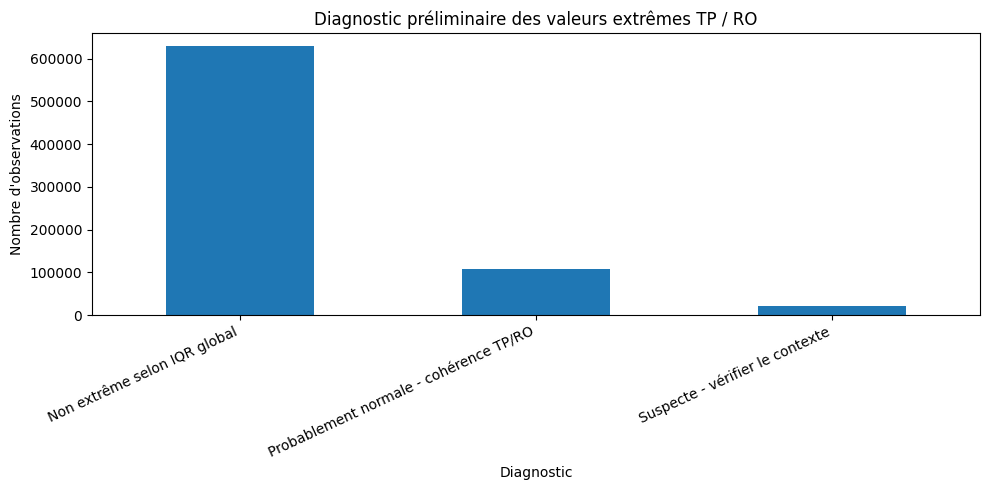

In [ ]:
import matplotlib.pyplot as plt

counts = validation["diagnostic"].value_counts()

plt.figure(figsize=(10, 5))
counts.plot(kind="bar")

plt.title("Diagnostic préliminaire des valeurs extrêmes TP / RO")
plt.xlabel("Diagnostic")
plt.ylabel("Nombre d'observations")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
# Sélectionner les observations où une seule variable est extrême
suspectes = validation[
    (validation["tp_high"] & ~validation["ro_high"]) |
    (~validation["tp_high"] & validation["ro_high"])
].copy()

# Identifier quelle variable est extrême
suspectes["type_outlier"] = np.where(
    suspectes["tp_high"],
    "TP uniquement",
    "RO uniquement"
)

# Nombre d'observations par date et par type
resume = (
    suspectes.groupby(["time", "type_outlier"])
    .size()
    .unstack(fill_value=0)
)

print("Nombre de dates concernées :", len(resume))
print("\nRépartition temporelle :")
print(resume.describe())

# Afficher les dates ayant le plus d'observations suspectes
print("\nDates les plus concernées :")
print(
    suspectes.groupby(["time", "type_outlier"])
    .size()
    .sort_values(ascending=False)
    .head(15)
)

Nombre de dates concernées : 140

Répartition temporelle :
type_outlier  RO uniquement  TP uniquement
count            140.000000     140.000000
mean             107.678571      48.514286
std               75.696314      68.007351
min                9.000000       0.000000
25%               48.000000       5.750000
50%               90.500000      19.500000
75%              140.250000      58.000000
max              353.000000     309.000000

Dates les plus concernées :
time        type_outlier 
2015-07-01  RO uniquement    353
2015-04-01  RO uniquement    337
2016-07-01  RO uniquement    317
2019-06-01  RO uniquement    311
2026-03-01  TP uniquement    309
2015-12-01  RO uniquement    297
2016-08-01  RO uniquement    295
2017-03-01  TP uniquement    292
2018-07-01  RO uniquement    281
2020-02-01  RO uniquement    279
2017-07-01  RO uniquement    266
2017-12-01  TP uniquement    244
2020-07-01  RO uniquement    238
2025-12-01  TP uniquement    236
2022-06-01  RO uniquement    235
dtyp

In [ ]:
# Ajouter le mois à partir de la date
suspectes["month"] = pd.to_datetime(suspectes["time"]).dt.month

# Nombre de cellules signalées par type et par mois
monthly_outliers = (
    suspectes
    .groupby(["month", "type_outlier"])
    .size()
    .unstack(fill_value=0)
)

print(monthly_outliers)

type_outlier  RO uniquement  TP uniquement
month                                     
1                       713            500
2                      1230            669
3                      1064           1389
4                       939            449
5                       727            388
6                      1762            217
7                      2804            121
8                      2070            426
9                       964            723
10                     1008            373
11                      714            697
12                     1080            840


In [ ]:
# Conserver toutes les observations
data_clean = data.copy()

# Vérifier qu'aucune observation n'a été supprimée
print("Dimensions initiales :", data.shape)
print("Dimensions après traitement :", data_clean.shape)

# Vérifier les valeurs manquantes
print(data_clean.isnull().sum())

Dimensions initiales : (759500, 12)
Dimensions après traitement : (759500, 12)
t2m     0
d2m     0
sp      0
u10     0
v10     0
slhf    0
sshf    0
ssr     0
str     0
e       0
ro      0
tp      0
dtype: int64


----------

In [ ]:
# ==========================================
# ANALYSE DE COHERENCE TP + E
# ==========================================

# Identifier les outliers de TP
tp_high = (
    (df_analysis["tp"] > df_analysis["tp"].quantile(0.75)
     + 1.5 * (
         df_analysis["tp"].quantile(0.75)
         - df_analysis["tp"].quantile(0.25)
     ))
)

# Identifier les outliers inférieurs de E
e_low = df_analysis["e"] < lower_bound

# Identifier les observations simultanément extrêmes
both_extreme = tp_high & e_low

# Identifier les observations extrêmes dans une seule variable
tp_only = tp_high & ~e_low
e_only = ~tp_high & e_low

# Résumé
print("===== DIAGNOSTIC TP / E =====")

print("TP élevés :", tp_high.sum())
print("E fortement négatifs :", e_low.sum())

print("TP et E extrêmes simultanément :", both_extreme.sum())

print("TP uniquement :", tp_only.sum())
print("E uniquement :", e_only.sum())

print("\n===== POURCENTAGES =====")

print(
    "TP élevés accompagnés de E extrême :",
    round(100 * both_extreme.sum() / tp_high.sum(), 2), "%"
)

print(
    "E extrêmes accompagnés de TP élevé :",
    round(100 * both_extreme.sum() / e_low.sum(), 2), "%"
)

===== DIAGNOSTIC TP / E =====
TP élevés : 115479
E fortement négatifs : 128044
TP et E extrêmes simultanément : 106285
TP uniquement : 9194
E uniquement : 21759

===== POURCENTAGES =====
TP élevés accompagnés de E extrême : 92.04 %
E extrêmes accompagnés de TP élevé : 83.01 %


In [ ]:
# Examiner la distribution de E

print("===== DISTRIBUTION DE E =====")

print(df_analysis["e"].describe(
    percentiles=[0.01, 0.25, 0.50, 0.75, 0.95, 0.99]
))

# Examiner les bornes IQR
Q1 = df_analysis["e"].quantile(0.25)
Q3 = df_analysis["e"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("\n===== BORNES IQR DE E =====")
print("Q1 :", Q1)
print("Q3 :", Q3)
print("IQR :", IQR)
print("Borne inférieure :", lower_bound)
print("Borne supérieure :", upper_bound)

# Identifier les outliers positifs et négatifs
e_low = df_analysis["e"] < lower_bound
e_high = df_analysis["e"] > upper_bound

print("\n===== OUTLIERS DE E =====")
print("Outliers inférieurs :", e_low.sum())
print("Outliers supérieurs :", e_high.sum())
print("Total des outliers :", (e_low | e_high).sum())

===== DISTRIBUTION DE E =====
count    759500.000000
mean         -0.000209
std           0.000404
min          -0.004697
1%           -0.002128
25%          -0.000131
50%          -0.000075
75%          -0.000040
95%          -0.000019
99%          -0.000014
max          -0.000008
Name: e, dtype: float64

===== BORNES IQR DE E =====
Q1 : -0.000130900414660573
Q3 : -4.0276325307786465e-05
IQR : 9.062408935278654e-05
Borne inférieure : -0.0002668365486897528
Borne supérieure : 9.565980872139335e-05

===== OUTLIERS DE E =====
Outliers inférieurs : 128044
Outliers supérieurs : 0
Total des outliers : 128044


-------------------

In [ ]:
print("===== DISTRIBUTION DE SLHF =====")

print(
    df_analysis["slhf"].describe(
        percentiles=[0.01, 0.25, 0.50, 0.75, 0.95, 0.99]
    )
)

# Calcul des bornes IQR
Q1 = df_analysis["slhf"].quantile(0.25)
Q3 = df_analysis["slhf"].quantile(0.75)

IQR = Q3 - Q1

lower_slhf = Q1 - 1.5 * IQR
upper_slhf = Q3 + 1.5 * IQR

# Détection des deux catégories d'outliers
slhf_low = df_analysis["slhf"] < lower_slhf
slhf_high = df_analysis["slhf"] > upper_slhf

print("\n===== BORNES IQR =====")
print("Q1 :", Q1)
print("Q3 :", Q3)
print("Borne inférieure :", lower_slhf)
print("Borne supérieure :", upper_slhf)

print("\n===== OUTLIERS =====")
print("Outliers inférieurs :", slhf_low.sum())
print("Outliers supérieurs :", slhf_high.sum())
print("Total :", (slhf_low | slhf_high).sum())

===== DISTRIBUTION DE SLHF =====
count    7.595000e+05
mean    -5.214472e+05
std      1.009670e+06
min     -1.174688e+07
1%      -5.322016e+06
25%     -3.273561e+05
50%     -1.887292e+05
75%     -1.007234e+05
95%     -4.651998e+04
99%     -3.616699e+04
max     -2.029050e+04
Name: slhf, dtype: float64

===== BORNES IQR =====
Q1 : -327356.125
Q3 : -100723.375
Borne inférieure : -667305.25
Borne supérieure : 239225.75

===== OUTLIERS =====
Outliers inférieurs : 128045
Outliers supérieurs : 0
Total : 128045


In [ ]:
# Identification des outliers inférieurs
e_low = df_analysis["e"] < lower_bound
slhf_low = df_analysis["slhf"] < lower_slhf

# Comparaison
both_low = e_low & slhf_low
e_only = e_low & ~slhf_low
slhf_only = slhf_low & ~e_low

print("===== COMPARAISON E ET SLHF =====")
print("Outliers E :", e_low.sum())
print("Outliers SLHF :", slhf_low.sum())

print("Outliers simultanés :", both_low.sum())
print("Outliers E uniquement :", e_only.sum())
print("Outliers SLHF uniquement :", slhf_only.sum())

print("\n===== POURCENTAGES DE COÏNCIDENCE =====")
print(
    "Outliers E accompagnés de SLHF extrême :",
    round(both_low.sum() / e_low.sum() * 100, 2), "%"
)

print(
    "Outliers SLHF accompagnés de E extrême :",
    round(both_low.sum() / slhf_low.sum() * 100, 2), "%"
)

===== COMPARAISON E ET SLHF =====
Outliers E : 128044
Outliers SLHF : 128045
Outliers simultanés : 128044
Outliers E uniquement : 0
Outliers SLHF uniquement : 1

===== POURCENTAGES DE COÏNCIDENCE =====
Outliers E accompagnés de SLHF extrême : 100.0 %
Outliers SLHF accompagnés de E extrême : 100.0 %


In [ ]:
# Corrélation entre E et SLHF
print("Corrélation E / SLHF :",
      df_analysis[["e", "slhf"]].corr().iloc[0, 1])

# Identification de l'observation différente
print("\nObservation SLHF uniquement :")

print(
    df_analysis.loc[
        slhf_only,
        ["time", "latitude", "longitude", "e", "slhf"]
    ]
)

Corrélation E / SLHF : 0.9999999096654271

Observation SLHF uniquement :
             time  latitude  longitude         e      slhf
926697 2023-01-01     34.55       2.75 -0.000266 -669167.0


In [ ]:
# Groupe 1 : toutes les observations
corr_all = df_analysis[["e", "slhf"]].corr().iloc[0, 1]

# Groupe 2 : observations sans outliers dans les deux variables
normal_mask = ~(e_low | slhf_low)

corr_normal = (
    df_analysis.loc[normal_mask, ["e", "slhf"]]
    .corr()
    .iloc[0, 1]
)

# Groupe 3 : observations présentant des outliers simultanément
extreme_mask = e_low & slhf_low

corr_extreme = (
    df_analysis.loc[extreme_mask, ["e", "slhf"]]
    .corr()
    .iloc[0, 1]
)

print("Corrélation sur toutes les observations :", corr_all)
print("Corrélation sans les outliers :", corr_normal)
print("Corrélation sur les outliers simultanés :", corr_extreme)

Corrélation sur toutes les observations : 0.9999999096654271
Corrélation sans les outliers : 0.9999999591403937
Corrélation sur les outliers simultanés : 0.9999997882675937


-----------------------------------

In [ ]:
# Fonction de détection des outliers par IQR
def detect_iqr_outliers(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    return (series < lower) | (series > upper), lower, upper


# Détection des outliers
t2m_outliers, t2m_lower, t2m_upper = detect_iqr_outliers(
    data["t2m"]
)

d2m_outliers, d2m_lower, d2m_upper = detect_iqr_outliers(
    data["d2m"]
)

# SLHF : uniquement les outliers inférieurs
slhf_outliers = data["slhf"] < lower_slhf


# Résultats
print("===== OUTLIERS =====")
print("SLHF :", slhf_outliers.sum())
print("T2M :", t2m_outliers.sum())
print("D2M :", d2m_outliers.sum())

print("\n===== BORNES IQR =====")
print("T2M :", t2m_lower, "à", t2m_upper)
print("D2M :", d2m_lower, "à", d2m_upper)

===== OUTLIERS =====
SLHF : 128045
T2M : 0
D2M : 8874

===== BORNES IQR =====
T2M : -6.655096435546852 à 54.73479614257815
D2M : -11.171972656249977 à 13.913964843750023


In [ ]:
# Masques des outliers
slhf_outliers = data["slhf"] < lower_slhf

d2m_outliers = (
    (data["d2m"] < d2m_lower) |
    (data["d2m"] > d2m_upper)
)

# Comparaison
both = slhf_outliers & d2m_outliers

slhf_only = slhf_outliers & ~d2m_outliers
d2m_only = d2m_outliers & ~slhf_outliers

print("===== COMPARAISON SLHF ET D2M =====")
print("Outliers SLHF :", slhf_outliers.sum())
print("Outliers D2M :", d2m_outliers.sum())
print("Outliers simultanés :", both.sum())
print("SLHF uniquement :", slhf_only.sum())
print("D2M uniquement :", d2m_only.sum())

print("\n===== POURCENTAGES =====")
print(
    "Outliers SLHF accompagnés de D2M :",
    round(both.sum() / slhf_outliers.sum() * 100, 2), "%"
)

print(
    "Outliers D2M accompagnés de SLHF :",
    round(both.sum() / d2m_outliers.sum() * 100, 2), "%"
)

===== COMPARAISON SLHF ET D2M =====
Outliers SLHF : 128045
Outliers D2M : 8874
Outliers simultanés : 7308
SLHF uniquement : 120737
D2M uniquement : 1566

===== POURCENTAGES =====
Outliers SLHF accompagnés de D2M : 5.71 %
Outliers D2M accompagnés de SLHF : 82.35 %


In [ ]:
# Séparation des observations selon les outliers de SLHF
t2m_slhf_extreme = data.loc[slhf_outliers, "t2m"]
t2m_normal = data.loc[~slhf_outliers, "t2m"]

# Statistiques comparatives
print("===== T2M SELON LES OUTLIERS DE SLHF =====")

print("\nT2M lorsque SLHF est extrême :")
print(t2m_slhf_extreme.describe(
    percentiles=[0.01, 0.25, 0.50, 0.75, 0.99]
))

print("\nT2M lorsque SLHF est normal :")
print(t2m_normal.describe(
    percentiles=[0.01, 0.25, 0.50, 0.75, 0.99]
))

===== T2M SELON LES OUTLIERS DE SLHF =====

T2M lorsque SLHF est extrême :
count    128045.000000
mean         17.526181
std           7.375160
min           0.275049
1%            4.506025
25%          11.323145
50%          16.961084
75%          23.563379
99%          33.278223
max          39.103418
Name: t2m, dtype: float64

T2M lorsque SLHF est normal :
count    631455.000000
mean         25.133935
std           8.457165
min           3.738916
1%            8.791650
25%          17.562891
50%          26.135889
75%          32.757959
99%          38.532241
max          41.029688
Name: t2m, dtype: float64


In [ ]:
# Ajouter le mois à chaque observation
df_analysis["month"] = df_analysis["time"].dt.month

# Comparaison mensuelle des températures
monthly_comparison = (
    df_analysis.groupby(
        ["month", slhf_outliers]
    )["t2m"]
    .agg(["count", "mean", "median"])
    .unstack()
)

monthly_comparison.columns = [
    f"{stat}_{'SLHF_extreme' if flag else 'SLHF_normal'}"
    for stat, flag in monthly_comparison.columns
]

print("===== COMPARAISON MENSUELLE T2M =====")
display(monthly_comparison.round(2))

===== COMPARAISON MENSUELLE T2M =====


,count_SLHF_normal,count_SLHF_extreme,mean_SLHF_normal,mean_SLHF_extreme,median_SLHF_normal,median_SLHF_extreme
month,,,,,,
1,55578,9522,12.68,7.82,12.57,7.53
2,53765,11335,16.07,10.13,15.97,10.06
3,48689,16411,20.42,14.25,20.18,13.92
4,51379,13721,25.52,17.82,25.61,16.86
5,54392,10708,29.96,20.73,29.99,20.00
6,56874,8226,33.53,25.17,33.70,24.79
7,59451,5649,35.10,28.15,35.35,27.94
8,56663,8437,34.52,28.47,34.64,27.84
9,47546,12129,31.88,25.34,31.95,24.55


In [ ]:
# Nombre total d'observations par mois
monthly_total = df_analysis.groupby("month").size()

# Nombre d'outliers SLHF par mois
monthly_extreme = (
    df_analysis[slhf_outliers]
    .groupby("month")
    .size()
)

# Pourcentage mensuel
monthly_rate = (
    monthly_extreme / monthly_total * 100
).rename("Pourcentage_outliers_SLHF")

print("===== TAUX MENSUEL DES OUTLIERS SLHF =====")
display(monthly_rate.round(2).to_frame())

===== TAUX MENSUEL DES OUTLIERS SLHF =====


,Pourcentage_outliers_SLHF
month,
1,14.63
2,17.41
3,25.21
4,21.08
5,16.45
6,12.64
7,8.68
8,12.96
9,20.33
